# 2D U-Net ornament segmentation (ROD + PB), version 2

What this notebook does, step by step:

1. **GPU check**: uses the laptop GPU through the local runtime. If no GPU is visible it stops with an error. It never switches to the CPU.
2. **Cached data only**: loads the saved ROD and PB constant-Q features, the frame labels, the segments and the original train / validation / test splits from `rod_koopman/cache/`. Nothing is downloaded, separated or re-extracted.
3. **Splits**: the cached splits are used unchanged (ROD: 137 / 24 / 43 recordings, with the official ROD test set; PB: 30 / 6 / 6 clips).
4. **Classes**: `Mu` and `An` have too few examples to learn (ROD training split: 24 Mu and 20 An segments), so they are **relabelled as `none`**. The model predicts **5 classes**: `none, K, H, Me, G`.
5. **Preprocessing**: removes silence only at the **start and end** of each recording, then applies per-frequency-bin normalisation (statistics from the training recordings only). Validation and test recordings are trimmed from the audio alone, without looking at their labels.
6. **Model**: a 2D U-Net over the whole CQT of a recording, followed by an optional **temporal context module** (a dilated temporal convolution stack or a bidirectional GRU) so each frame's prediction can use several seconds of context.
7. **Training**: plain cross-entropy loss (no class weights, no augmentation), one full recording per step, optional cosine learning-rate schedule. The checkpoint is chosen on a 3-epoch moving average of validation F1 (less sensitive to a single lucky epoch).
8. **Hyperparameter search**: random search over all settings jointly, then the best configurations are re-trained with several seeds and the configuration with the best **mean** validation score is selected. The test set is not used here.
9. **Test evaluation**: every seed of the selected configuration is evaluated once on the held-out test recordings; mean and standard deviation are reported.

All results of this version are written to `rod_koopman/unet_seg_v2/`. The earlier results in `rod_koopman/unet_seg/` are left untouched.

## 1. GPU runtime check

In [1]:
import os, sys, time, json, math, random, pickle, gc
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

print('python :', sys.executable)
print('torch  :', torch.__version__, '| CUDA build:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU is visible to PyTorch in this kernel. Stopping instead of falling back to the CPU. '
                       'Check that the notebook is connected to the local runtime that has the CUDA build of torch.')
DEV = torch.device('cuda:0')
_p = torch.cuda.get_device_properties(0)
_free, _total = torch.cuda.mem_get_info()
print(f'GPU    : {_p.name} | {_total / 2**30:.2f} GiB total, {_free / 2**30:.2f} GiB free | compute capability {_p.major}.{_p.minor}')
# Recordings have different lengths. cuDNN autotuning would re-benchmark for every new length (very slow), so it is off.
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('mixed precision dtype:', AMP_DTYPE)
_a = torch.randn(1024, 1024, device=DEV); _ = float((_a @ _a).sum()); del _a
print('GPU compute check OK')

SEED = 2035
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

python : C:\Users\YOGESH KRISHNA\Desktop\proj\Environments\jupy-env\Scripts\python.exe
torch  : 2.14.1+cu130 | CUDA build: 13.0
GPU    : NVIDIA GeForce RTX 3050 A Laptop GPU | 4.00 GiB total, 2.98 GiB free | compute capability 8.9
mixed precision dtype: torch.bfloat16
GPU compute check OK


## 2. Load the cached features, labels and splits

In [2]:
PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rod_koopman' / 'cache').is_dir())
CACHE = PROJ / 'rod_koopman' / 'cache'
# Version-2 results go to a NEW folder, so the earlier experiments in rod_koopman/unet_seg/ are never overwritten.
# (UNET_OUT and UNET_SMOKE are only set for a quick end-to-end test of the code; a normal run does not need them.)
OUT = Path(os.environ.get('UNET_OUT', PROJ / 'rod_koopman' / 'unet_seg_v2')); OUT.mkdir(parents=True, exist_ok=True)
RUNS = OUT / 'runs'; RUNS.mkdir(exist_ok=True)
SMOKE = os.environ.get('UNET_SMOKE') == '1'
print('cache :', CACHE); print('output:', OUT)
if SMOKE: print('*** SMOKE TEST MODE: tiny budgets, the numbers are meaningless ***')

ORIG_CLASSES = ['none', 'K', 'H', 'Me', 'G', 'Mu', 'An']   # classes in the cached labels
DROPPED = ('Mu', 'An')                                     # too few examples -> relabelled as 'none'
CLASSES = [c for c in ORIG_CLASSES if c not in DROPPED]    # 0 = no ornament
C2I = {c: i for i, c in enumerate(CLASSES)}; NC = len(CLASSES); IGNORE = -100
SPLITS = ('train', 'val', 'test')
_REMAP = np.array([C2I.get(c, 0) for c in ORIG_CLASSES])   # cached class index -> new index (Mu, An -> none)

def drop_classes(t):
    y = t['y'].copy(); lab = y != IGNORE; y[lab] = _REMAP[y[lab]]
    return dict(t, y=y, segs=[s for s in t['segs'] if s[2] not in DROPPED])

KEEP = ('id', 'dataset', 'audio', 'x', 'fps', 'segs', 'y', 'dur', 'split')
RAW = {}
for name in ('ROD', 'PB'):
    t0 = time.time()
    orig = [{k: t[k] for k in KEEP if k in t} for t in pickle.loads((CACHE / f'{name}_tracks.pkl').read_bytes())]
    n_drop = sum(1 for t in orig for *_, l in t['segs'] if l in DROPPED)
    RAW[name] = [drop_classes(t) for t in orig]
    tr = RAW[name]
    print(f"{name}: {len(tr)} recordings | {tr[0]['x'].shape[1]} constant-Q bins @ {tr[0]['fps']} frames/s "
          f"| {n_drop} Mu/An segments relabelled as 'none' | loaded in {time.time() - t0:.1f}s")
del orig
print('classes:', CLASSES)

# ---- the cached splits are used unchanged; their recording lists are saved and fingerprinted ----
SPLIT_LISTS = {name: {s: sorted(t['id'] for t in RAW[name] if t['split'] == s) for s in SPLITS} for name in RAW}
(OUT / 'splits.json').write_text(json.dumps(SPLIT_LISTS, indent=1))
for name in RAW:
    print(f"{name} split (recordings): " + ', '.join(f'{s} {len(v)}' for s, v in SPLIT_LISTS[name].items()))

cache : C:\Users\YOGESH KRISHNA\Desktop\smai-project\smai-project\rod_koopman\cache
output: C:\Users\YOGESH KRISHNA\Desktop\smai-project\smai-project\rod_koopman\unet_seg_v2
ROD: 204 recordings | 216 constant-Q bins @ 100.0 frames/s | 113 Mu/An segments relabelled as 'none' | loaded in 1.5s
PB: 42 recordings | 141 constant-Q bins @ 56.8 frames/s | 44 Mu/An segments relabelled as 'none' | loaded in 0.1s
classes: ['none', 'K', 'H', 'Me', 'G']
ROD split (recordings): train 137, val 24, test 43
PB split (recordings): train 30, val 6, test 6


In [3]:
# ---- integrity checks (the cached splits are used exactly as they are) ----
def check(tracks, name):
    ids = {s: {t['id'] for t in tracks if t['split'] == s} for s in SPLITS}
    assert not (ids['train'] & ids['val']) and not (ids['train'] & ids['test']) and not (ids['val'] & ids['test'])
    if 'audio' in tracks[0]:                       # the same recording is never in two splits
        rec = {}
        for t in tracks:
            rec.setdefault(os.path.basename(t['audio']), set()).add(t['split'])
        assert all(len(v) == 1 for v in rec.values()), 'a recording appears in more than one split'
    bad = tot = 0                                  # frame labels agree with the segment list
    for t in tracks:
        assert len(t['x']) == len(t['y'])
        for s, e, l in t['segs']:
            if l is None: continue
            i = min(int((s + e) / 2 * t['fps']), len(t['y']) - 1); tot += 1; bad += int(t['y'][i] != C2I[l])
    assert bad <= 0.01 * tot, f'{bad} label mismatches'
    print(f'{name}: splits disjoint, {tot - bad}/{tot} labelled segments consistent with the frame labels '
          f'({bad} nested inside another annotation)')
    return bad

def summary(tracks):
    rows = []
    for s in SPLITS:
        ts = [t for t in tracks if t['split'] == s]
        y = np.concatenate([t['y'] for t in ts]); n = Counter(l for t in ts for *_, l in t['segs'] if l)
        rows.append(dict(split=s, recordings=len(ts), minutes=round(sum(t['dur'] for t in ts) / 60, 1),
                         ornament_frames=round(float(np.mean(y[y != IGNORE] > 0)), 3), **{c: n.get(c, 0) for c in CLASSES[1:]}))
    return pd.DataFrame(rows).set_index('split')

BAD_RAW = {}
for name in RAW:
    BAD_RAW[name] = check(RAW[name], name); display(summary(RAW[name]))

ROD: splits disjoint, 3781/3781 labelled segments consistent with the frame labels (0 nested inside another annotation)


,recordings,minutes,ornament_frames,K,H,Me,G
split,,,,,,,
train,137,90.5,0.344,657,1090,710,70
val,24,14.6,0.314,95,154,113,11
test,43,35.1,0.308,241,360,256,24


PB: splits disjoint, 365/366 labelled segments consistent with the frame labels (1 nested inside another annotation)


,recordings,minutes,ornament_frames,K,H,Me,G
split,,,,,,,
train,30,15.1,0.377,78,72,56,54
val,6,3.0,0.396,17,7,4,17
test,6,3.0,0.372,19,21,14,7


## 3. Preprocessing step: remove silence at the start and end of each recording

Many recordings begin (and some end) with several seconds of silence. This step removes **only** that leading and trailing silence. Nothing is removed from the middle of a recording.

How it works, for each recording:

* **Loudness of each frame** = the loudest constant-Q bin in that frame, in dB. ROD features are already in dB; PB magnitudes are converted with $20\log_{10}$.
* **Reference level** = the 95th percentile of the frame loudness, i.e. the typical loud level of that recording.
* A frame counts as **sound** if it is at most 40 dB below the reference level. Quiet notes are rarely this far down: in ROD only 0.07% of ornament frames are.
* The recording is cut just before the first sound frame and just after the last one, keeping a **0.2 s safety margin** on each side.
* **Safety rule (training recordings only)**: the cut never reaches into an annotated segment or a labelled frame. If an annotation starts earlier than the detected sound, the cut moves back to keep it (plus the margin).
* **Validation and test recordings are trimmed from the audio alone**: their labels must not influence their own preprocessing. The checks afterwards only *verify* that no annotated frame was cut (the run stops with an error if one was).
* Edge silences shorter than 0.5 s are left alone.
* The features `x` and the frame labels `y` are cut with the same frame indices. Segment timestamps are shifted by the same amount (`start_frame / fps`), so all three stay aligned. The same method is applied to train, validation and test.

In [4]:
SIL_DB, MARGIN_S, MIN_TRIM_S = 40.0, 0.2, 0.5

def loudness_db(t):
    e = t['x'].max(1).astype(np.float64)
    return e if t['dataset'] == 'ROD' else 20 * np.log10(e + 1e-5)

def trim_edges(t):
    fps, T = t['fps'], len(t['y'])
    e = loudness_db(t); ref = np.percentile(e, 95)
    m = int(round(MARGIN_S * fps))
    sound = np.flatnonzero(e >= ref - SIL_DB)
    a, b = (max(0, sound[0] - m), min(T, sound[-1] + 1 + m)) if len(sound) else (0, T)
    if t['split'] == 'train':
        # safety rule, TRAINING recordings only. Validation/test recordings are cut from the audio alone,
        # so their labels never influence their own preprocessing (the checks below only verify nothing was lost).
        lab = np.flatnonzero(t['y'] != 0)                          # ornament (or ignored) frames are never removed
        times = [v for s, e_, _ in t['segs'] for v in (s, e_)]       # nor any annotated segment
        if len(lab): a, b = min(a, max(0, lab[0] - m)), max(b, min(T, lab[-1] + 1 + m))
        if times: a, b = min(a, max(0, int(np.floor(min(times) * fps)) - m)), max(b, min(T, int(np.ceil(max(times) * fps)) + m))
    if a < MIN_TRIM_S * fps: a = 0
    if T - b < MIN_TRIM_S * fps: b = T
    off = a / fps
    new = dict(t, x=t['x'][a:b], y=t['y'][a:b], segs=[(s - off, e_ - off, l) for s, e_, l in t['segs']],
               dur=(b - a) / fps, trim=(int(a), int(b), int(T)), ref_db=float(ref))
    # ---- alignment checks ----
    assert (t['y'][:a] == 0).all() and (t['y'][b:] == 0).all(), f"trimming would remove a labelled frame ({t['split']} recording {t['id']})"
    assert all(-1e-6 <= s and e_ <= new['dur'] + 1e-6 for s, e_, _ in new['segs']), 'a segment falls outside the trimmed recording'
    for (s0, e0, l), (s1, e1, _) in zip(t['segs'], new['segs']):   # same label at every segment's midpoint
        i0 = min(int((s0 + e0) / 2 * fps), T - 1); i1 = min(int((s1 + e1) / 2 * fps), b - a - 1)
        assert t['y'][i0] == new['y'][i1]
    return new

D = {name: [trim_edges(t) for t in RAW[name]] for name in RAW}
for name in D:                                   # the whole integrity check again, on the trimmed data
    assert check(D[name], name + ' (after trimming)') == BAD_RAW[name]

rows = []
for name in D:
    for s in SPLITS:
        ts = [t for t in D[name] if t['split'] == s]
        lead = np.array([t['trim'][0] for t in ts]) / ts[0]['fps']; tail = np.array([t['trim'][2] - t['trim'][1] for t in ts]) / ts[0]['fps']
        tot = sum(t['trim'][2] for t in ts) / ts[0]['fps']
        rows.append(dict(dataset=name, split=s, recordings=len(ts), trimmed_recordings=int(np.sum((lead > 0) | (tail > 0))),
                         lead_removed_s_total=lead.sum().round(1), tail_removed_s_total=tail.sum().round(1),
                         lead_removed_s_max=lead.max().round(1), percent_of_audio_removed=round(100 * (lead.sum() + tail.sum()) / tot, 1)))
display(pd.DataFrame(rows).set_index(['dataset', 'split']))
for name in D: display(summary(D[name]).rename_axis(f'{name} after trimming'))

ROD (after trimming): splits disjoint, 3781/3781 labelled segments consistent with the frame labels (0 nested inside another annotation)
PB (after trimming): splits disjoint, 365/366 labelled segments consistent with the frame labels (1 nested inside another annotation)


recordings  trimmed_recordings  lead_removed_s_total  \
dataset split                                                         
ROD     train         137                 105                 709.0   
        val            24                  20                 136.8   
        test           43                  33                 231.8   
PB      train          30                   7                  22.0   
        val             6                   0                   0.0   
        test            6                   1                   0.0   

               tail_removed_s_total  lead_removed_s_max  \
dataset split                                             
ROD     train                  39.1                21.4   
        val                     8.3                17.5   
        test                   13.1                17.5   
PB      train                   5.7                 9.2   
        val                     0.0                 0.0   
        test                    2.1                 0.0   

               percent_of_audio_removed  
dataset split                            
ROD     train                      13.8  
        val                        16.5  
        test                       11.6  
PB      train                       3.1  
        val                         0.0  
        test                        1.2

,recordings,minutes,ornament_frames,K,H,Me,G
ROD after trimming,,,,,,,
train,137,78.0,0.399,657,1090,710,70
val,24,12.2,0.376,95,154,113,11
test,43,31.1,0.348,241,360,256,24


,recordings,minutes,ornament_frames,K,H,Me,G
PB after trimming,,,,,,,
train,30,14.6,0.388,78,72,56,54
val,6,3.0,0.396,17,7,4,17
test,6,3.0,0.377,19,21,14,7


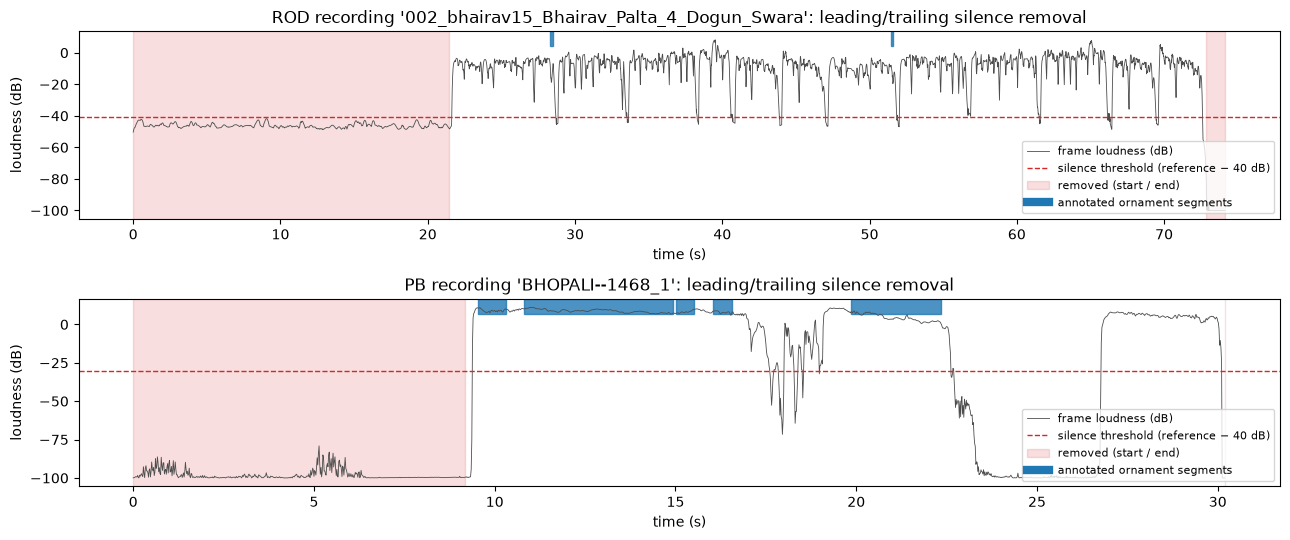

In [5]:
# ---- what the trimming does on two example recordings ----
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5))
for ax, name in zip(axes, ('ROD', 'PB')):
    t = max(RAW[name], key=lambda r: [x for x in D[name] if x['id'] == r['id']][0]['trim'][0])   # most leading silence
    tt = next(x for x in D[name] if x['id'] == t['id']); a, b, T = tt['trim']; fps = t['fps']
    e = loudness_db(t); time_s = np.arange(T) / fps
    ax.plot(time_s, e, lw=0.6, color='0.3', label='frame loudness (dB)')
    ax.axhline(tt['ref_db'] - SIL_DB, color='tab:red', ls='--', lw=1, label=f'silence threshold (reference − {SIL_DB:.0f} dB)')
    ax.axvspan(0, a / fps, color='tab:red', alpha=0.15, label='removed (start / end)')
    ax.axvspan(b / fps, T / fps, color='tab:red', alpha=0.15)
    for s, e_, l in t['segs']:
        if l: ax.axvspan(s, e_, ymin=0.92, ymax=1.0, color='tab:blue', alpha=0.8)
    ax.plot([], [], color='tab:blue', lw=6, label='annotated ornament segments')
    ax.set(title=f"{name} recording '{t['id']}': leading/trailing silence removal", xlabel='time (s)', ylabel='loudness (dB)')
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

## 4. Normalisation

Every constant-Q bin is standardised to zero mean and unit variance. The mean and standard deviation come from the **trimmed training recordings only**, separately for ROD and PB, and the same statistics are applied to validation and test. Nothing else is done to the features: no augmentation, no frequency masking, no extra features.

In [6]:
class SegData:
    def __init__(s, tracks):
        s.name, s.fps = tracks[0]['dataset'], float(tracks[0]['fps'])
        s.tracks = {sp: [t for t in tracks if t['split'] == sp] for sp in SPLITS}
        X = np.concatenate([t['x'] for t in s.tracks['train']]).astype(np.float64)
        s.mu, s.sd = X.mean(0).astype(np.float32), (X.std(0) + 1e-5).astype(np.float32)
        s.n_feat = X.shape[1]
        # (freq, time) per recording, kept on the CPU and copied to the GPU one recording at a time
        s.x = {t['id']: torch.from_numpy(((t['x'] - s.mu) / s.sd).T.astype(np.float16).copy()) for t in tracks}
        s.y = {t['id']: torch.from_numpy(t['y'].astype(np.int64)) for t in tracks}
        s.longest = {sp: max(ts, key=lambda t: len(t['y'])) for sp, ts in s.tracks.items()}

    def get(s, t):     # -> x: (1, 1, F, T) float32, y: (1, T)
        return s.x[t['id']].to(DEV, non_blocking=True).float()[None, None], s.y[t['id']].to(DEV)[None]

DATA = {name: SegData(D[name]) for name in D}
for name, d in DATA.items():
    xtr = torch.cat([d.x[t['id']].float() for t in d.tracks['train']], 1)
    print(f"{name}: train-normalised features mean {xtr.mean():.3f}, std {xtr.std():.3f} | longest recording per split (frames): "
          + ', '.join(f"{sp}={len(d.longest[sp]['y'])}" for sp in SPLITS))
del xtr

ROD: train-normalised features mean 0.000, std 1.000 | longest recording per split (frames): train=15363, val=9649, test=15370
PB: train-normalised features mean -0.000, std 1.000 | longest recording per split (frames): train=1716, val=1716, test=1716


## 5. Evaluation metrics

Predicted segments are the runs of a single ornament class in the raw per-frame argmax predictions (no post-processing). Each predicted segment is matched one-to-one (greedy, by IoU) to a ground-truth segment **of the same class** with temporal IoU ≥ 0.5.

* **Precision** = matched / predicted segments, **Recall** = matched / ground-truth segments, **F1** = their harmonic mean. This segment F1 is the number used to choose models.
* **IoU**: frame-level IoU per ornament class, macro-averaged (`IoU_macro`); ornament-vs-none IoU (`IoU_orn`); mean IoU of the matched segments (`IoU_matched`).
* **Segment Jaccard** (`seg_jaccard`) = TP / (TP + FP + FN). (Called "segment-level accuracy" in version 1; it is not an accuracy, so it was renamed.) A segment counts as correct only if its class and its extent (IoU ≥ 0.5) are both right. Missed and spurious segments both count as errors.
* **Per-class**: segment-level P / R / F1 for each ornament class (plus that class's **frame-level** IoU, now named `frame_IoU` so it is not mistaken for a segment metric), and frame-level P / R / F1 / IoU for all classes (including `none`).

In [7]:
def runs(lab):
    lab = np.asarray(lab)
    if len(lab) == 0: return []
    ch = np.flatnonzero(np.diff(lab)) + 1
    st, en = np.r_[0, ch], np.r_[ch, len(lab)]
    return [(int(a), int(b), int(lab[a])) for a, b in zip(st, en) if lab[a] > 0]

def match(pred, gt, thr, class_aware=True):
    if not pred or not gt: return []
    P, G = np.array(pred, float), np.array(gt, float)
    inter = np.clip(np.minimum(P[:, None, 1], G[None, :, 1]) - np.maximum(P[:, None, 0], G[None, :, 0]), 0, None)
    union = np.maximum(P[:, None, 1], G[None, :, 1]) - np.minimum(P[:, None, 0], G[None, :, 0])
    iou = inter / np.maximum(union, 1e-9)
    if class_aware: iou = np.where(P[:, None, 2] == G[None, :, 2], iou, 0.0)
    ii, jj = np.nonzero(iou >= thr)
    used_p, used_g, pairs = set(), set(), []
    for k in np.argsort(-iou[ii, jj], kind='stable'):
        i, j = int(ii[k]), int(jj[k])
        if i not in used_p and j not in used_g:
            used_p.add(i); used_g.add(j); pairs.append((i, j, float(iou[i, j])))
    return pairs

def evaluate(labs, tracks, thr=0.5, tol=0.1):
    tp = tp_any = tp30 = n_pred = n_gt = n_bnd = 0
    ious, inter, union = [], np.zeros(NC), np.zeros(NC)
    i_orn = u_orn = corr = n_valid = 0
    c_tp, c_np, c_ng = np.zeros(NC), np.zeros(NC), np.zeros(NC)
    for t in tracks:
        lab, y, fps = labs[t['id']], t['y'], t['fps']
        valid = y != IGNORE
        pred = [(s / fps, e / fps, c) for s, e, c in runs(np.where(valid, lab, 0))]
        gt = [(s, e, C2I[l]) for s, e, l in t['segs'] if l is not None]
        pairs = match(pred, gt, thr)
        tp += len(pairs); n_pred += len(pred); n_gt += len(gt)
        tp_any += len(match(pred, gt, thr, class_aware=False)); tp30 += len(match(pred, gt, 0.3))
        ious += [p[2] for p in pairs]
        n_bnd += sum(abs(pred[i][0] - gt[j][0]) <= tol and abs(pred[i][1] - gt[j][1]) <= tol for i, j, _ in pairs)
        for i, j, _ in pairs: c_tp[gt[j][2]] += 1
        for p in pred: c_np[p[2]] += 1
        for g in gt: c_ng[g[2]] += 1
        lv, yv = lab[valid], y[valid]
        for c in range(1, NC):
            inter[c] += np.sum((lv == c) & (yv == c)); union[c] += np.sum((lv == c) | (yv == c))
        i_orn += np.sum((lv > 0) & (yv > 0)); u_orn += np.sum((lv > 0) | (yv > 0))
        corr += np.sum(lv == yv); n_valid += len(yv)
    f1 = lambda a, b: 2 * a * b / max(a + b, 1e-9)
    P, R = tp / max(n_pred, 1), tp / max(n_gt, 1)
    Pa, Ra = tp_any / max(n_pred, 1), tp_any / max(n_gt, 1)
    present = [c for c in range(1, NC) if c_ng[c] > 0]
    out = dict(P=P, R=R, F1=f1(P, R), F1_any=f1(Pa, Ra), F1_iou30=f1(tp30 / max(n_pred, 1), tp30 / max(n_gt, 1)),
               IoU_macro=float(np.mean([inter[c] / max(union[c], 1) for c in present])),
               IoU_orn=i_orn / max(u_orn, 1), IoU_matched=float(np.mean(ious)) if ious else 0.0,
               seg_jaccard=tp / max(n_pred + n_gt - tp, 1), boundary_acc=n_bnd / max(n_gt, 1),
               frame_acc=corr / max(n_valid, 1), n_pred=n_pred, n_gt=n_gt)
    per_class = {CLASSES[c]: dict(P=c_tp[c] / max(c_np[c], 1), R=c_tp[c] / c_ng[c],
                                  F1=f1(c_tp[c] / max(c_np[c], 1), c_tp[c] / c_ng[c]),
                                  frame_IoU=inter[c] / max(union[c], 1), n_gt=int(c_ng[c]), n_pred=int(c_np[c])) for c in present}
    return out, per_class

def frame_report(labs, tracks):
    cm = np.zeros((NC, NC), np.int64)
    for t in tracks:
        y = t['y']; v = y != IGNORE
        np.add.at(cm, (y[v], labs[t['id']][v]), 1)
    tp = np.diag(cm).astype(float); npred, ngt = cm.sum(0), cm.sum(1)
    P, R = tp / np.maximum(npred, 1), tp / np.maximum(ngt, 1)
    return pd.DataFrame(dict(precision=P, recall=R, F1=2 * P * R / np.maximum(P + R, 1e-9),
                             IoU=tp / np.maximum(npred + ngt - tp, 1), gt_frames=ngt, pred_frames=npred), index=CLASSES), cm

# self-test: K predicted exactly; H predicted as Me -> P = R = 0.5, class-agnostic F1 = 1, seg_jaccard = 1/3
_t = dict(id='t', fps=10.0, y=np.array([0, 1, 1, 1, 0, 0, 2, 2, 0, 0]), segs=[(0.1, 0.4, 'K'), (0.6, 0.8, 'H')])
_m, _ = evaluate({'t': np.array([0, 1, 1, 1, 0, 0, 3, 3, 3, 0])}, [_t])
assert _m['P'] == 0.5 and _m['R'] == 0.5 and _m['F1_any'] == 1.0 and abs(_m['seg_jaccard'] - 1 / 3) < 1e-9 and _m['IoU_macro'] == 0.5
print('metric self-test passed')

metric self-test passed


## 6. Model: 2D U-Net + temporal context module

The CQT of a whole recording is treated as a one-channel image: frequency × time.

* **Encoder**: at each level, two 3×3 convolutions (each followed by BatchNorm and ReLU), then 2×2 max-pooling. Channels `base → 2·base → …`.
* **Bottleneck**: two 3×3 convolutions with `base·2^levels` channels.
* **Decoder**: a 2×2 transposed convolution upsamples, the result is concatenated with the encoder features at the same level (**skip connection**), then two 3×3 convolutions.
* **Why a temporal module**: in version 1 the measured receptive field was only ~0.9 s (3 levels) to ~2 s (4 levels), and most of the influence came from the nearest ~0.8 s. Long ornaments (G: median 2.1 s, up to 18 s) and the shapes that separate classes over several seconds cannot be seen in such a window, and every frame was decided almost on its own, which fragments segments.
* **Temporal module** (`temporal` setting):
  * `none`: as in version 1, a convolution spanning the whole frequency axis gives 7→5 class scores per frame.
  * `tcn`: the frequency axis is collapsed into a `t_ch`-dimensional vector per frame, then `t_depth` residual dilated 1-D convolutions (kernel 3, dilation 1, 2, 4, …) mix information along time. Each block adds `2·dilation` frames, so the module adds `2·(2^t_depth − 1)` frames: 126 (6 blocks), 510 (8) or 2046 (10) frames, i.e. 1.3 / 5.1 / 20 s on ROD and 2.2 / 9 / 36 s on PB.
  * `gru`: same collapse, then a `t_depth`-layer **bidirectional GRU**: every frame can use the whole recording.
* The input is zero-padded so frequency and time are multiples of 2^levels; the padding is cut off before the temporal module and at the output.
* Optional dropout (a search setting) in the bottleneck, decoder and temporal blocks.
* `receptive_field()` measures the receptive field of a trained model directly: it back-propagates from one output frame to the input and reports which input frames influence it.

In [8]:
class ConvBlock(nn.Sequential):
    def __init__(s, ci, co, dropout=0.0):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         *([nn.Dropout2d(dropout)] if dropout > 0 else []))

class TemporalBlock(nn.Module):
    """Residual dilated 1-D convolution along time: adds 2*dilation frames of context."""
    def __init__(s, ch, dilation, dropout=0.0):
        super().__init__()
        s.net = nn.Sequential(nn.Conv1d(ch, ch, 3, padding=dilation, dilation=dilation, bias=False), nn.BatchNorm1d(ch),
                              nn.ReLU(inplace=True), *([nn.Dropout(dropout)] if dropout > 0 else []))
    def forward(s, x): return x + s.net(x)

class UNet2D(nn.Module):
    def __init__(s, n_freq, n_cls=NC, base=16, levels=3, dropout=0.0, temporal='none', t_ch=64, t_depth=8):
        super().__init__()
        s.mult = 2 ** levels
        s.Fp = -(-n_freq // s.mult) * s.mult                       # padded frequency size
        chs = [base * 2 ** i for i in range(levels)]                # e.g. 16, 32, 64
        s.enc, c = nn.ModuleList(), 1
        for co in chs:
            s.enc.append(ConvBlock(c, co)); c = co
        s.pool = nn.MaxPool2d(2)
        s.bottleneck = ConvBlock(c, base * 2 ** levels, dropout); c = base * 2 ** levels   # e.g. 128
        s.up, s.dec = nn.ModuleList(), nn.ModuleList()
        for co in reversed(chs):
            s.up.append(nn.ConvTranspose2d(c, co, 2, stride=2))
            s.dec.append(ConvBlock(2 * co, co, dropout)); c = co
        s.temporal_kind = temporal
        if temporal == 'none':
            s.head = nn.Conv2d(c, n_cls, kernel_size=(s.Fp, 1))    # whole frequency axis -> class scores per frame
        else:
            s.collapse = nn.Sequential(nn.Conv2d(c, t_ch, kernel_size=(s.Fp, 1), bias=False), nn.BatchNorm2d(t_ch), nn.ReLU(inplace=True))
            if temporal == 'tcn':
                s.temporal = nn.Sequential(*[TemporalBlock(t_ch, 2 ** i, dropout) for i in range(t_depth)])
            elif temporal == 'gru':
                s.temporal = nn.GRU(t_ch, t_ch // 2, num_layers=t_depth, batch_first=True, bidirectional=True,
                                    dropout=dropout if t_depth > 1 else 0.0)
            else:
                raise ValueError(temporal)
            s.out = nn.Conv1d(t_ch, n_cls, 1)

    def forward(s, x):                                              # x: (B, 1, F, T) -> logits (B, n_cls, T)
        B, _, Fq, T = x.shape
        x = F.pad(x, (0, (-T) % s.mult, 0, s.Fp - Fq))
        skips = []
        for enc in s.enc:
            x = enc(x); skips.append(x); x = s.pool(x)
        x = s.bottleneck(x)
        for up, dec in zip(s.up, s.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        if s.temporal_kind == 'none':
            return s.head(x)[:, :, 0, :T]
        h = s.collapse(x)[:, :, 0, :T]                              # (B, t_ch, T); time padding removed before temporal mixing
        if s.temporal_kind == 'tcn':
            h = s.temporal(h)
        else:
            with torch.autocast('cuda', enabled=False):              # the GRU runs in float32
                h = s.temporal(h.float().transpose(1, 2))[0].transpose(1, 2)
        return s.out(h)

def build_model(cfg, data):
    return UNet2D(data.n_feat, NC, cfg['base'], cfg['levels'], cfg['dropout'],
                  cfg.get('temporal', 'none'), cfg.get('t_ch', 64), cfg.get('t_depth', 8)).to(DEV)

def make_optimizer(cfg, model):
    if cfg['optim'] == 'adam':  return torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'adamw': return torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'sgd':   return torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    raise ValueError(cfg['optim'])

def receptive_field(model, data, tracks, max_frames=4000):
    """Measured temporal receptive field: which input frames influence the output at the centre frame."""
    t = max(tracks, key=lambda t: len(t['y'])); x, _ = data.get(t)
    x = x[..., :max_frames].clone().requires_grad_(True); T = x.shape[-1]; c = T // 2
    model.eval()
    # cuDNN can only back-propagate through a GRU in training mode, so cuDNN is switched off for the GRU case
    with torch.enable_grad(), torch.backends.cudnn.flags(enabled=model.temporal_kind != 'gru'):
        model(x)[0, :, c].abs().sum().backward()
    g = x.grad[0, 0].abs().sum(0).cpu().numpy(); nz = np.flatnonzero(g > 0)
    cs = np.cumsum(g) / g.sum(); lo, hi = np.searchsorted(cs, 0.05), np.searchsorted(cs, 0.95)
    model.zero_grad(set_to_none=True)
    return dict(theoretical_s=(nz[-1] - nz[0] + 1) / data.fps, effective90_s=(hi - lo + 1) / data.fps,
                window_s=T / data.fps, reaches_window_edge=bool(nz[0] == 0 or nz[-1] == T - 1))

# default settings (version-1 starting U-Net); every configuration of the search fills in these keys
BASE = dict(lr=1e-3, optim='adam', wd=0.0, dropout=0.0, base=16, levels=3, temporal='none', t_ch=64, t_depth=8, sched='none')
for _cfg in (BASE, dict(BASE, temporal='tcn'), dict(BASE, temporal='gru', t_depth=1)):
    _m = build_model(_cfg, DATA['ROD'])
    with torch.no_grad():
        _o = _m(torch.zeros(1, 1, DATA['ROD'].n_feat, 1000, device=DEV))
    print(f"temporal={_cfg['temporal']:4s}: {sum(p.numel() for p in _m.parameters()) / 1e6:.3f} M parameters | input (1, 1, 216, 1000) -> output {tuple(_o.shape)}")
    del _m, _o
torch.cuda.empty_cache()

temporal=none: 0.500 M parameters | input (1, 1, 216, 1000) -> output (1, 5, 1000)
temporal=tcn : 0.803 M parameters | input (1, 1, 216, 1000) -> output (1, 5, 1000)
temporal=gru : 0.723 M parameters | input (1, 1, 216, 1000) -> output (1, 5, 1000)


## 7. GPU memory check on the longest recording

Training uses one **entire** recording per step: no crops, no shortening. Before training, one full training step (forward pass, backward pass and optimiser update) is run on the **longest training recording**, and its peak GPU memory is compared with the free GPU memory.

On Windows the GPU driver can spill into **shared system memory (RAM)** when the GPU's own memory is full, instead of raising an out-of-memory error. This still gives correct results, but it is slower: on this laptop a base-32 U-Net step on the longest recording took 7.9 s, against 0.5 s for the base-16 model that fits in GPU memory. The extra work of the bigger model explains only about 4× of that gap.

* `ALLOW_SHARED_MEMORY = True` (used here): such configurations are trained anyway and are **flagged** as `uses_shared_memory` in the results, so their slower run times are visible.
* `ALLOW_SHARED_MEMORY = False`: they are reported as a memory error and not trained.

A real CUDA out-of-memory error is always reported, and that experiment is marked as failed. Recordings are never shortened.

In [9]:
MEM_SAFETY = 0.95
ALLOW_SHARED_MEMORY = True     # 24 GB system RAM: allow (slower) spill into shared memory, but flag it

def memory_check(cfg, data):
    gc.collect(); torch.cuda.empty_cache()
    free = torch.cuda.mem_get_info()[0]; r0 = torch.cuda.memory_reserved()
    torch.cuda.reset_peak_memory_stats()
    t = data.longest['train']; model = opt = None; err = None; peak = float('nan')
    try:
        model = build_model(cfg, data); opt = make_optimizer(cfg, model)
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        F.cross_entropy(logits.float(), y, ignore_index=IGNORE).backward(); opt.step(); torch.cuda.synchronize()
        peak = torch.cuda.max_memory_reserved() - r0
    except torch.OutOfMemoryError:
        err = 'CUDA out of memory during a full-recording training step'
    model = opt = x = y = logits = None; gc.collect(); torch.cuda.empty_cache()
    spills = err is None and peak > MEM_SAFETY * free
    msg = (f'needs {peak / 2**20:.0f} MiB but only {free / 2**20:.0f} MiB of GPU memory is free '
           f'-> spills into shared system memory (slower)') if spills else None
    ok = err is None and (not spills or ALLOW_SHARED_MEMORY)
    if err is None and not ok: err = msg
    return dict(ok=ok, uses_shared_memory=spills, peak_MiB=peak / 2**20, free_MiB=free / 2**20, frames=len(t['y']),
                seconds=len(t['y']) / data.fps, error=err, note=msg)

rows = []
for name, d in DATA.items():
    mc = memory_check(BASE, d); rows.append(dict(dataset=name, **mc))
display(pd.DataFrame(rows).set_index('dataset').round(1))
for r in rows:
    if not r['ok']:
        raise RuntimeError(f"MEMORY ISSUE ({r['dataset']}): the starting U-Net does not fit for the longest training recording "
                           f"({r['frames']} frames): {r['error']}. Recordings are NOT shortened and random crops are NOT used.")
for r in rows:
    print(f"{r['dataset']}: starting U-Net " + (f"WARNING - {r['note']}" if r['uses_shared_memory'] else 'fits in GPU memory')
          + f" for the longest training recording ({r['frames']} frames, {r['seconds']:.0f} s)")

,ok,uses_shared_memory,peak_MiB,free_MiB,frames,seconds,error,note
dataset,,,,,,,,
ROD,True,True,3014.0,3013.8,15363,153.6,None,needs 3014 MiB but only 3014 MiB of GPU memory...
PB,True,False,212.0,3202.2,1716,30.2,None,NaN


ROD: starting U-Net WARNING - needs 3014 MiB but only 3014 MiB of GPU memory is free -> spills into shared system memory (slower) for the longest training recording (15363 frames, 154 s)
PB: starting U-Net fits in GPU memory for the longest training recording (1716 frames, 30 s)


## 8. Training

* **Loss**: ordinary `CrossEntropyLoss` over the 5 classes, **no class weights**. There is no reconstruction or other extra loss.
* **One full recording per step**, in a random order each epoch. No crops, no gain changes, no pitch shifting, no frequency masking.
* **Learning-rate schedule** (search setting `sched`): constant, or cosine decay over `max_epochs`.
* After every epoch the model predicts every validation recording in full. We record the training loss, validation loss and validation segment F1.
* **Checkpoint selection**: validation F1 jumps by about ±0.04 from one epoch to the next, so picking the single best epoch rewards luck. Instead we track the **3-epoch moving average** of validation F1 and keep the weights from the epoch that ends the best 3-epoch window. Early stopping also uses this moving average. The moving-average value is the **score** used to compare configurations; the single-epoch F1 of the kept weights is also stored.
* Mixed precision (bf16) is used to save GPU memory and time (the GRU runs in float32). Gradients are clipped at norm 1.
* Every experiment is saved to `rod_koopman/unet_seg_v2/runs/`: a `.json` file with the settings, seed, curves, metrics and status, and a `.pt` file with the kept weights. Re-running the notebook reuses a saved experiment **only if it was made with the same code version, budget, class list and train / val / test split**; otherwise it is trained again (version 1 reused any file with a matching name, even after the code had changed).

In [10]:
@torch.no_grad()
def predict(model, data, tracks):
    # full-recording inference -> per-frame argmax labels, and the frame-averaged cross-entropy
    model.eval(); labs, loss_sum, n = {}, 0.0, 0
    for t in tracks:
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        logits = logits.float()
        loss_sum += float(F.cross_entropy(logits, y, ignore_index=IGNORE, reduction='sum')); n += int((y != IGNORE).sum())
        labs[t['id']] = logits[0].argmax(0).cpu().numpy()
    return labs, loss_sum / max(n, 1)

MA_WINDOW = 3          # epochs in the moving average of validation F1 used for checkpointing and comparison
CODE_VERSION = 'v2'    # stored in every saved experiment; a saved result from other code is not reused
import hashlib
def split_id(ds):      # fingerprint of the train / val / test recording lists
    return hashlib.md5(json.dumps(SPLIT_LISTS[ds], sort_keys=True).encode()).hexdigest()[:12]

def train_run(cfg, data, max_epochs, patience, seed=SEED, log_every=5):
    seed_all(seed); rng = np.random.default_rng(seed)
    model = build_model(cfg, data); opt = make_optimizer(cfg, model)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs) if cfg.get('sched', 'none') == 'cosine' else None
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE == torch.float16)
    train = data.tracks['train']
    hist, best, best_ep, best_val, best_state, bad, status, t0 = [], -1.0, 0, None, None, 0, 'ok', time.time()
    torch.cuda.reset_peak_memory_stats()
    for ep in range(1, max_epochs + 1):
        model.train(); ls, n = 0.0, 0
        for i in rng.permutation(len(train)):
            x, y = data.get(train[i])
            with torch.autocast('cuda', dtype=AMP_DTYPE):
                logits = model(x)
            loss = F.cross_entropy(logits.float(), y, ignore_index=IGNORE)
            if not torch.isfinite(loss.detach()):
                status = 'failed: non-finite training loss'; break
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            k = int((y != IGNORE).sum()); ls += loss.item() * k; n += k
        if status != 'ok':
            print(f'    epoch {ep}: {status} - run stopped'); break
        if sched is not None: sched.step()
        labs, vloss = predict(model, data, data.tracks['val'])
        m, _ = evaluate(labs, data.tracks['val'])
        hist.append(dict(epoch=ep, train_loss=ls / n, val_loss=vloss, val_F1=m['F1'], val_IoU=m['IoU_macro'],
                         val_seg_jaccard=m['seg_jaccard'], val_frame_acc=m['frame_acc'], lr=opt.param_groups[0]['lr'], sec=time.time() - t0))
        ma = float(np.mean([h['val_F1'] for h in hist[-MA_WINDOW:]])); hist[-1]['val_F1_ma'] = ma
        if ma > best:
            best, best_ep, best_val, bad = ma, ep, m, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % log_every == 0 or ep == 1 or bad >= patience or ep == max_epochs:
            h = hist[-1]
            print(f"    ep {ep:3d} | train loss {h['train_loss']:.3f} | val loss {h['val_loss']:.3f} | val F1 {h['val_F1']:.3f} "
                  f"(3-ep avg {ma:.3f}) | best avg {best:.3f} @ep{best_ep} | {h['sec'] / 60:.1f} min", flush=True)
        if bad >= patience: break
    peak = torch.cuda.max_memory_allocated() / 2**20
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    if best_state is None and status == 'ok': status = 'failed: no completed epoch'
    ok = best_state is not None
    return dict(status=status, best_epoch=best_ep, best_val_F1_ma=best if ok else float('nan'),
                best_val_F1=best_val['F1'] if ok else float('nan'), best_val=best_val, hist=hist, epochs_run=len(hist),
                minutes=(time.time() - t0) / 60, train_peak_MiB=peak), best_state

def tag_of(ds, cfg, seed=SEED):
    c = {**BASE, **cfg}
    tag = f"{ds}_lr{c['lr']:.2g}_{c['optim']}_wd{c['wd']:g}_do{c['dropout']:g}_b{c['base']}_L{c['levels']}_{c['temporal']}"
    if c['temporal'] != 'none': tag += f"{c['t_depth']}x{c['t_ch']}"
    return tag + f"_{c['sched']}_s{seed}"

def run_experiment(ds, cfg, seed=SEED):
    cfg = {**BASE, **cfg}; data, tag = DATA[ds], tag_of(ds, cfg, seed); jf = RUNS / f'{tag}.json'
    if jf.exists():
        r = json.loads(jf.read_text())
        if (r.get('code_version') == CODE_VERSION and r.get('budget') == BUDGET[ds] and r.get('classes') == CLASSES
                and r.get('split_id') == split_id(ds)):
            print(f"  [saved result reused] {tag}: {r['status']} | val F1 3-ep avg {r['best_val_F1_ma']:.3f}"); return r
        print(f'  [saved result NOT reused: made with different code, budget, classes or split] {tag}')
    print(f'  training {tag}')
    r = dict(tag=tag, dataset=ds, seed=seed, code_version=CODE_VERSION, budget=BUDGET[ds], classes=CLASSES, split_id=split_id(ds), **cfg)
    mc = memory_check(cfg, data)
    r.update(mem_peak_MiB=mc['peak_MiB'], mem_free_MiB=mc['free_MiB'], uses_shared_memory=mc['uses_shared_memory'])
    if mc['ok'] and mc['uses_shared_memory']:
        print(f"    NOTE: {mc['note']} - training anyway (ALLOW_SHARED_MEMORY=True)")
    if not mc['ok']:
        r.update(status='memory error', error=mc['error'], best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
        print(f"    MEMORY ERROR: {mc['error']} - this experiment was NOT trained (recordings are not shortened)")
    else:
        try:
            info, state = train_run(cfg, data, seed=seed, **BUDGET[ds])
            r.update(info, n_params=sum(v.numel() for k, v in state.items() if 'running' not in k and 'num_batches' not in k) if state else None)
            if state is not None:
                torch.save(dict(cfg=cfg, seed=seed, state=state, mu=data.mu, sd=data.sd, dataset=ds, classes=CLASSES), RUNS / f'{tag}.pt')
        except torch.OutOfMemoryError as e:
            r.update(status='memory error', error=f'CUDA out of memory during training: {e}', best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
            print('    MEMORY ERROR during training:', e)
        except Exception as e:
            r.update(status='failed', error=repr(e), best_val_F1=float('nan'), best_val_F1_ma=float('nan'), hist=[], epochs_run=0)
            print('    EXPERIMENT FAILED:', repr(e))
        gc.collect(); torch.cuda.empty_cache()
    if r['status'] != 'ok': r.setdefault('error', r['status'])
    jf.write_text(json.dumps(r, indent=1, default=float))
    return r

def load_model(tag):
    ck = torch.load(RUNS / f'{tag}.pt', map_location='cpu', weights_only=False)
    m = build_model(ck['cfg'], DATA[ck['dataset']]); m.load_state_dict(ck['state']); return m.eval()

## 9. Hyperparameter search (validation only)

Version 1 changed one setting at a time from a fixed starting point, with one seed per setting. That has three problems: settings that only work together (for example depth with dropout) are never tried together; the optimizer stage changed two things at once; and with one seed most of the differences between settings were smaller than the run-to-run noise (the 95% bootstrap interval of the selected ROD model's validation F1 was about ±0.06).

Version 2 uses a two-phase search:

**Phase 1: random search.** `N_TRIALS` configurations are drawn at random from the space below (all settings varied together), each trained once (seed `SEED`). Two **anchor** configurations are always included: the version-1 selected model, and the same model with a temporal convolution module, so the effect of the temporal context can be read off directly.

| setting | values |
|---|---|
| `lr` | log-uniform between 1e-4 and 3e-3 |
| `optim` | Adam, AdamW |
| `wd` | 0, 1e-5, 1e-4, 1e-3, 1e-2 |
| `dropout` | 0, 0.1, 0.2, 0.3, 0.4 |
| `base` (channels base → 2·base → …) | 12, 16 (larger does not fit in 4 GB for the longest ROD recording) |
| `levels` | 3, 4, 5 |
| `temporal` | none, tcn, gru |
| `t_depth` | tcn: 6, 8, 10 blocks (adds 1.3 / 5.1 / 20 s on ROD); gru: 1, 2 layers |
| `t_ch` | 32, 64 |
| `sched` | constant, cosine |

**Phase 2: seed confirmation.** The `TOP_K` best configurations of phase 1 are trained again with more seeds (`N_SEEDS` in total). The configuration with the highest **mean** score over its seeds is selected. Score = best 3-epoch moving average of validation F1 (section 8).

The test set is never looked at here. ROD and PB are searched separately, each on its own validation split.

Budget: up to 50 epochs (ROD) or 100 epochs (PB), stopping when the 3-epoch average of validation F1 hasn't improved for 10 (ROD) or 20 (PB) epochs. The ROD search takes several hours on the laptop GPU (roughly 30 runs of 8–15 min; more for runs that spill into shared memory). The PB search takes about an hour.

In [11]:
BUDGET = {'ROD': dict(max_epochs=50, patience=10), 'PB': dict(max_epochs=100, patience=20)}
N_TRIALS = {'ROD': 24, 'PB': 48}      # phase 1: random configurations, one seed each (anchors included)
TOP_K    = {'ROD': 3,  'PB': 4}       # phase 2: this many best configurations are re-trained ...
N_SEEDS  = {'ROD': 3,  'PB': 5}       # ... until they have this many seeds in total
SEARCH_SEED = 7                       # makes the list of random configurations reproducible

ANCHORS = {   # always evaluated: version-1 selected model, and the same model with a temporal convolution module
    'ROD': [dict(lr=3e-4, optim='adam', wd=1e-4, dropout=0.3, base=16, levels=4),
            dict(lr=3e-4, optim='adam', wd=1e-4, dropout=0.3, base=16, levels=4, temporal='tcn', t_depth=8, t_ch=64)],
    'PB':  [dict(lr=3e-4, optim='adam', wd=0.0, dropout=0.3, base=16, levels=3),
            dict(lr=3e-4, optim='adam', wd=0.0, dropout=0.3, base=16, levels=3, temporal='tcn', t_depth=8, t_ch=64)]}

if SMOKE:   # quick end-to-end test of the code only
    BUDGET = {'ROD': dict(max_epochs=2, patience=1), 'PB': dict(max_epochs=3, patience=1)}
    N_TRIALS, TOP_K, N_SEEDS = {'ROD': 3, 'PB': 4}, {'ROD': 2, 'PB': 2}, {'ROD': 2, 'PB': 2}
    for _ds in ANCHORS: ANCHORS[_ds].append(dict(ANCHORS[_ds][0], temporal='gru', t_depth=1, t_ch=32))

def sample_cfg(rng):
    temporal = str(rng.choice(['none', 'tcn', 'gru']))
    c = dict(lr=float(f'{10 ** rng.uniform(-4, np.log10(3e-3)):.2g}'), optim=str(rng.choice(['adam', 'adamw'])),
             wd=float(rng.choice([0.0, 1e-5, 1e-4, 1e-3, 1e-2])), dropout=float(rng.choice([0.0, 0.1, 0.2, 0.3, 0.4])),
             base=int(rng.choice([12, 16])), levels=int(rng.choice([3, 4, 5])), temporal=temporal,
             sched=str(rng.choice(['none', 'cosine'])))
    if temporal == 'tcn': c.update(t_depth=int(rng.choice([6, 8, 10])), t_ch=int(rng.choice([32, 64])))
    if temporal == 'gru': c.update(t_depth=int(rng.choice([1, 2])), t_ch=int(rng.choice([32, 64])))
    return {**BASE, **c}

def cfg_key(cfg): return tag_of('', cfg, 0)[1:-3]     # identifies a configuration independently of the seed

def search(ds):
    rng = np.random.default_rng(SEARCH_SEED + (0 if ds == 'ROD' else 1))
    cfgs, cfg_of = [], {}
    for c in [{**BASE, **a} for a in ANCHORS[ds]] + [sample_cfg(rng) for _ in range(20 * N_TRIALS[ds])]:
        k = cfg_key(c)
        if k not in cfg_of: cfg_of[k] = c; cfgs.append(c)
        if len(cfgs) == N_TRIALS[ds]: break
    rows, t0 = [], time.time()

    def record(r, phase):
        HIST[r['tag']] = r.get('hist', []); bv = r.get('best_val') or {}
        rows.append({**{k: r.get(k) for k in ('tag', *BASE, 'seed', 'status', 'best_val_F1_ma', 'best_val_F1', 'best_epoch',
                                              'epochs_run', 'minutes', 'n_params', 'mem_peak_MiB', 'uses_shared_memory', 'error')},
                     'dataset': ds, 'phase': phase, 'config': cfg_key({k: r[k] for k in BASE}),
                     'val_P': bv.get('P'), 'val_R': bv.get('R'), 'val_IoU': bv.get('IoU_macro'), 'val_seg_jaccard': bv.get('seg_jaccard')})

    for i, c in enumerate(cfgs):
        print(f'\n=== {ds} | phase 1 (random search) {i + 1}/{len(cfgs)}: {cfg_key(c)}')
        record(run_experiment(ds, c, SEED), 'phase 1: random search')
    p1 = [r for r in rows if r['status'] == 'ok']
    finalists = [r['config'] for r in sorted(p1, key=lambda r: -r['best_val_F1_ma'])[:TOP_K[ds]]]
    for k in finalists:
        for s in range(1, N_SEEDS[ds]):
            print(f'\n=== {ds} | phase 2 (seed confirmation) seed {SEED + s}: {k}')
            record(run_experiment(ds, cfg_of[k], SEED + s), 'phase 2: seed confirmation')

    res = pd.DataFrame(rows)
    agg = (res[res['status'] == 'ok'].groupby('config')
           .agg(n_seeds=('seed', 'nunique'), score_mean=('best_val_F1_ma', 'mean'), score_std=('best_val_F1_ma', 'std'),
                F1_mean=('best_val_F1', 'mean'), F1_std=('best_val_F1', 'std'), temporal=('temporal', 'first')))
    complete = agg[agg.index.isin(finalists) & (agg['n_seeds'] >= N_SEEDS[ds])]
    pool = complete if len(complete) else agg[agg.index.isin(finalists)]
    best = pool['score_mean'].idxmax(); cfg = cfg_of[best]
    seeds = sorted(res[(res['config'] == best) & (res['status'] == 'ok')]['seed'].astype(int).unique())
    sel = dict(key=best, cfg=cfg, tags=[tag_of(ds, cfg, s) for s in seeds], seeds=[int(s) for s in seeds],
               score_mean=float(pool.loc[best, 'score_mean']), score_std=float(np.nan_to_num(pool.loc[best, 'score_std'])),
               F1_mean=float(pool.loc[best, 'F1_mean']))
    res.to_csv(OUT / f'search_results_{ds}.csv', index=False); agg.to_csv(OUT / f'search_summary_{ds}.csv')
    print(f"\n{ds} search finished in {(time.time() - t0) / 60:.1f} min | selected {best} "
          f"(score {sel['score_mean']:.3f} +- {sel['score_std']:.3f} over {len(seeds)} seeds)")
    return res, agg, sel

RES, AGG, SELECTED, HIST = {}, {}, {}, {}
RES['ROD'], AGG['ROD'], SELECTED['ROD'] = search('ROD')


=== ROD | phase 1 (random search) 1/24: lr0.0003_adam_wd0.0001_do0.3_b16_L4_none_none
  training ROD_lr0.0003_adam_wd0.0001_do0.3_b16_L4_none_none_s2035
    NOTE: needs 3378 MiB but only 3202 MiB of GPU memory is free -> spills into shared system memory (slower) - training anyway (ALLOW_SHARED_MEMORY=True)
    ep   1 | train loss 1.081 | val loss 0.846 | val F1 0.051 (3-ep avg 0.051) | best avg 0.051 @ep1 | 4.8 min
    ep   5 | train loss 0.627 | val loss 0.683 | val F1 0.261 (3-ep avg 0.157) | best avg 0.157 @ep5 | 12.5 min
    ep  10 | train loss 0.479 | val loss 0.506 | val F1 0.398 (3-ep avg 0.340) | best avg 0.340 @ep10 | 16.2 min
    ep  15 | train loss 0.392 | val loss 0.510 | val F1 0.481 (3-ep avg 0.420) | best avg 0.420 @ep15 | 19.8 min
    ep  20 | train loss 0.320 | val loss 0.573 | val F1 0.545 (3-ep avg 0.503) | best avg 0.503 @ep20 | 23.6 min
    ep  25 | train loss 0.272 | val loss 0.629 | val F1 0.516 (3-ep avg 0.526) | best avg 0.526 @ep25 | 27.2 min
    ep  30 | tra

In [12]:
RES['PB'], AGG['PB'], SELECTED['PB'] = search('PB')


=== PB | phase 1 (random search) 1/48: lr0.0003_adam_wd0_do0.3_b16_L3_none_none
  training PB_lr0.0003_adam_wd0_do0.3_b16_L3_none_none_s2035
    ep   1 | train loss 1.270 | val loss 1.131 | val F1 0.000 (3-ep avg 0.000) | best avg 0.000 @ep1 | 0.0 min
    ep   5 | train loss 0.951 | val loss 1.250 | val F1 0.067 (3-ep avg 0.058) | best avg 0.058 @ep5 | 0.1 min
    ep  10 | train loss 0.764 | val loss 0.778 | val F1 0.193 (3-ep avg 0.138) | best avg 0.138 @ep10 | 0.2 min
    ep  15 | train loss 0.616 | val loss 0.940 | val F1 0.125 (3-ep avg 0.143) | best avg 0.155 @ep14 | 0.2 min
    ep  20 | train loss 0.442 | val loss 0.922 | val F1 0.115 (3-ep avg 0.123) | best avg 0.155 @ep14 | 0.3 min
    ep  25 | train loss 0.381 | val loss 1.470 | val F1 0.131 (3-ep avg 0.125) | best avg 0.160 @ep23 | 0.4 min
    ep  30 | train loss 0.260 | val loss 1.078 | val F1 0.250 (3-ep avg 0.202) | best avg 0.202 @ep30 | 0.5 min
    ep  35 | train loss 0.226 | val loss 1.241 | val F1 0.188 (3-ep avg 0.19

In [13]:
# ---- all experiments, the multi-seed comparison, and the selected configuration per dataset ----
cols = ['phase', 'seed', 'lr', 'optim', 'wd', 'dropout', 'base', 'levels', 'temporal', 't_depth', 't_ch', 'sched', 'status',
        'best_val_F1_ma', 'best_val_F1', 'val_P', 'val_R', 'val_IoU', 'val_seg_jaccard', 'best_epoch', 'epochs_run',
        'minutes', 'n_params', 'uses_shared_memory']
for ds in RES:
    print(f'{ds}: every experiment (validation; score = best 3-epoch average of validation F1)')
    display(RES[ds][cols].sort_values(['phase', 'best_val_F1_ma'], ascending=[True, False]).round(4))
    print(f'{ds}: configurations trained with more than one seed (mean and std over seeds)')
    display(AGG[ds][AGG[ds]['n_seeds'] > 1].sort_values('score_mean', ascending=False).round(4))
    s = SELECTED[ds]
    print(f"SELECTED {ds}: {s['key']} | score {s['score_mean']:.3f} +- {s['score_std']:.3f} over seeds {s['seeds']}")
    for _, r in RES[ds][RES[ds]['status'] != 'ok'].iterrows():
        print(f"  FAILED EXPERIMENT {r['tag']}: {r['status']} - {r['error']}")
pd.concat(RES.values()).to_csv(OUT / 'search_results_all.csv', index=False)
json.dump(SELECTED, open(OUT / 'selected_models.json', 'w'), indent=1, default=float)

ROD: every experiment (validation; score = best 3-epoch average of validation F1)


,phase,seed,lr,optim,wd,dropout,base,levels,temporal,t_depth,...,best_val_F1,val_P,val_R,val_IoU,val_seg_jaccard,best_epoch,epochs_run,minutes,n_params,uses_shared_memory
19,phase 1: random search,2035,0.0004,adam,0.0000,0.3,12,5,tcn,8,...,0.6457,0.6076,0.6890,0.5605,0.4768,44,50,14.6565,4487877,False
23,phase 1: random search,2035,0.0003,adamw,0.0001,0.2,16,5,gru,2,...,0.6355,0.5877,0.6917,0.5896,0.4657,22,32,13.1208,7902821,True
0,phase 1: random search,2035,0.0003,adam,0.0001,0.3,16,4,none,8,...,0.6128,0.5501,0.6917,0.5732,0.4418,41,50,45.3823,1960197,True
10,phase 1: random search,2035,0.0018,adamw,0.0010,0.3,12,5,none,8,...,0.5489,0.4550,0.6917,0.6353,0.3783,46,50,26.6333,4389989,False
11,phase 1: random search,2035,0.0006,adamw,0.0001,0.3,16,5,none,8,...,0.5760,0.5020,0.6756,0.6071,0.4045,50,50,62.7513,7796229,True
20,phase 1: random search,2035,0.0003,adamw,0.0001,0.3,12,3,gru,1,...,0.5645,0.5167,0.6220,0.5266,0.3932,34,44,16.8535,456837,False
7,phase 1: random search,2035,0.0008,adam,0.0001,0.1,12,4,gru,2,...,0.5402,0.5083,0.5764,0.4795,0.3701,22,32,8.3897,1188997,False
13,phase 1: random search,2035,0.0004,adamw,0.0100,0.1,16,4,gru,1,...,0.5470,0.4967,0.6086,0.5832,0.3765,38,48,19.7864,2190917,True
5,phase 1: random search,2035,0.0015,adamw,0.0010,0.1,16,4,gru,2,...,0.5452,0.5974,0.5013,0.4531,0.3747,21,31,9.2179,2066789,True
1,phase 1: random search,2035,0.0003,adam,0.0001,0.3,16,4,tcn,8,...,0.5135,0.4412,0.6139,0.5012,0.3454,22,32,13.6039,2271429,True


ROD: configurations trained with more than one seed (mean and std over seeds)


,n_seeds,score_mean,score_std,F1_mean,F1_std,temporal
config,,,,,,
lr0.0004_adam_wd1e-05_do0.3_b12_L5_tcn8x32_cosine,3,0.6156,0.0191,0.6165,0.0291,tcn
lr0.00033_adamw_wd0.0001_do0.2_b16_L5_gru2x32_cosine,3,0.6125,0.0158,0.6137,0.0261,gru
lr0.0003_adam_wd0.0001_do0.3_b16_L4_none_none,3,0.5826,0.0085,0.5936,0.0374,none


SELECTED ROD: lr0.0004_adam_wd1e-05_do0.3_b12_L5_tcn8x32_cosine | score 0.616 +- 0.019 over seeds [2035, 2036, 2037]
PB: every experiment (validation; score = best 3-epoch average of validation F1)


,phase,seed,lr,optim,wd,dropout,base,levels,temporal,t_depth,...,best_val_F1,val_P,val_R,val_IoU,val_seg_jaccard,best_epoch,epochs_run,minutes,n_params,uses_shared_memory
45,phase 1: random search,2035,0.0022,adam,0.000,0.4,12,5,gru,2,...,0.4444,0.5000,0.4000,0.2718,0.2857,52,72,2.2865,4537509,False
2,phase 1: random search,2035,0.0029,adam,0.000,0.1,16,5,gru,2,...,0.4416,0.5312,0.3778,0.2874,0.2833,21,41,1.1044,7870053,False
42,phase 1: random search,2035,0.0026,adamw,0.010,0.3,12,4,gru,2,...,0.4000,0.4000,0.4000,0.3672,0.2500,18,38,0.7392,1158277,False
27,phase 1: random search,2035,0.0024,adamw,0.001,0.3,12,5,gru,2,...,0.3918,0.3654,0.4222,0.3489,0.2436,50,70,2.3274,4537509,False
36,phase 1: random search,2035,0.0021,adamw,0.000,0.4,12,5,gru,1,...,0.3810,0.3333,0.4444,0.2467,0.2353,39,59,1.7986,4518693,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,phase 2: seed confirmation,2038,0.0024,adamw,0.001,0.3,12,5,gru,2,...,0.3590,0.4242,0.3111,0.3012,0.2188,14,34,1.0612,4537509,False
54,phase 2: seed confirmation,2038,0.0029,adam,0.000,0.1,16,5,gru,2,...,0.3590,0.4242,0.3111,0.2471,0.2188,13,33,0.8870,7870053,False
55,phase 2: seed confirmation,2039,0.0029,adam,0.000,0.1,16,5,gru,2,...,0.3571,0.2985,0.4444,0.2648,0.2174,25,45,1.2114,7870053,False
57,phase 2: seed confirmation,2037,0.0026,adamw,0.010,0.3,12,4,gru,2,...,0.3056,0.4074,0.2444,0.2568,0.1803,14,34,0.6446,1158277,False


PB: configurations trained with more than one seed (mean and std over seeds)


,n_seeds,score_mean,score_std,F1_mean,F1_std,temporal
config,,,,,,
lr0.0022_adam_wd0_do0.4_b12_L5_gru2x64_cosine,5,0.4255,0.0102,0.4376,0.0118,gru
lr0.0024_adamw_wd0.001_do0.3_b12_L5_gru2x64_cosine,5,0.4139,0.0368,0.4169,0.0477,gru
lr0.0026_adamw_wd0.01_do0.3_b12_L4_gru2x32_cosine,5,0.3826,0.0382,0.3764,0.0464,gru
lr0.0029_adam_wd0_do0.1_b16_L5_gru2x32_cosine,5,0.3817,0.0315,0.3949,0.0385,gru


SELECTED PB: lr0.0022_adam_wd0_do0.4_b12_L5_gru2x64_cosine | score 0.426 +- 0.010 over seeds [2035, 2036, 2037, 2038, 2039]


## 10. Plots of the search

1. Validation F1 (3-epoch average) and training / validation loss over the epochs, for every phase-1 experiment, coloured by temporal module.
2. Phase-1 score against each hyperparameter (one dot per experiment).
3. The configurations re-trained with several seeds: mean ± std, with every seed shown.

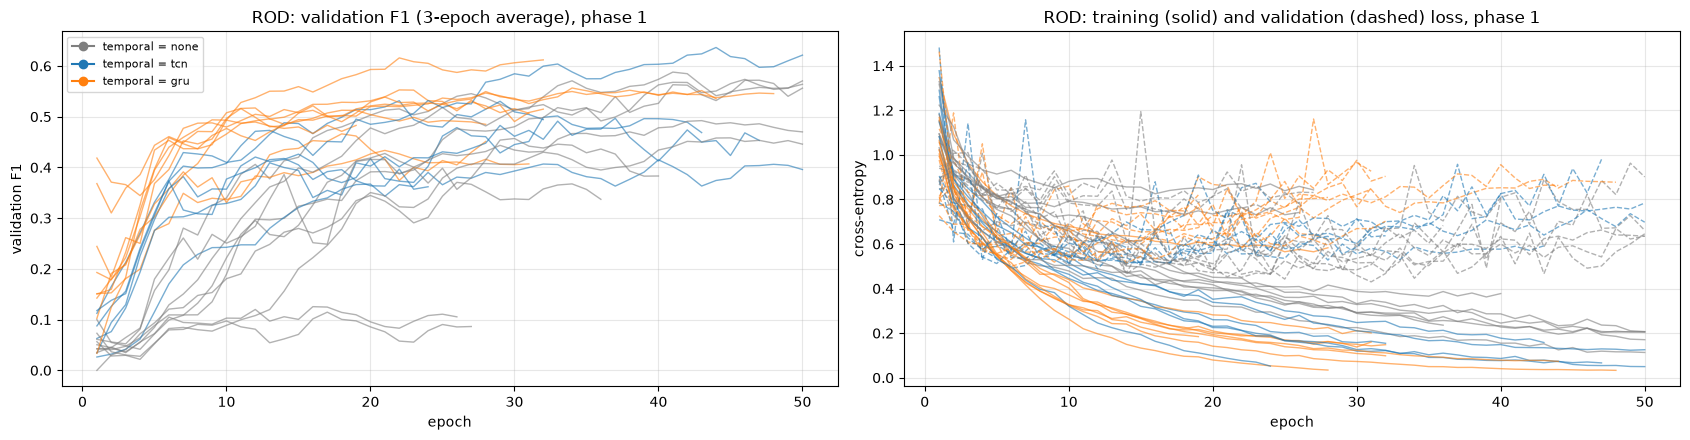

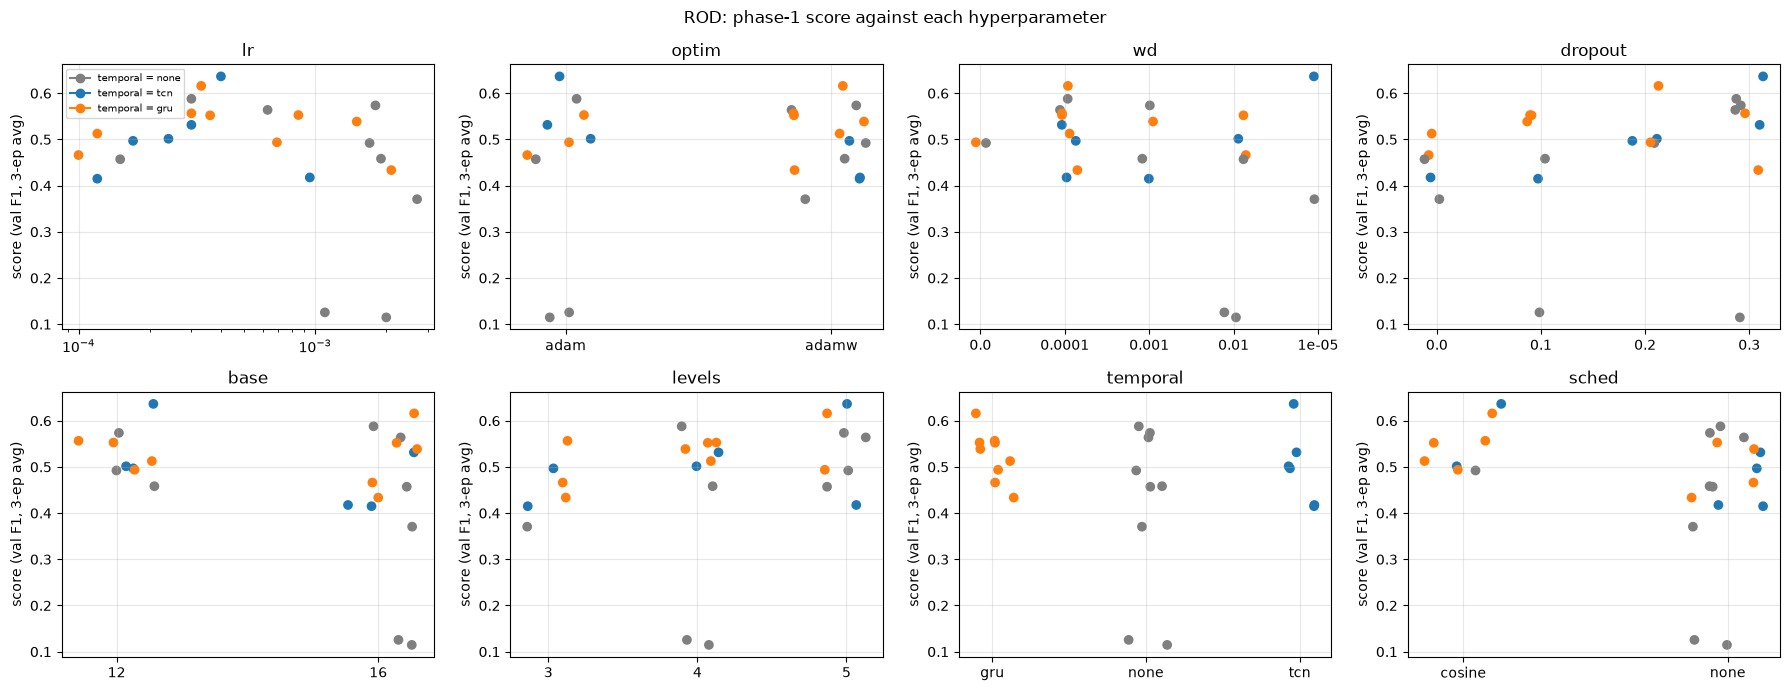

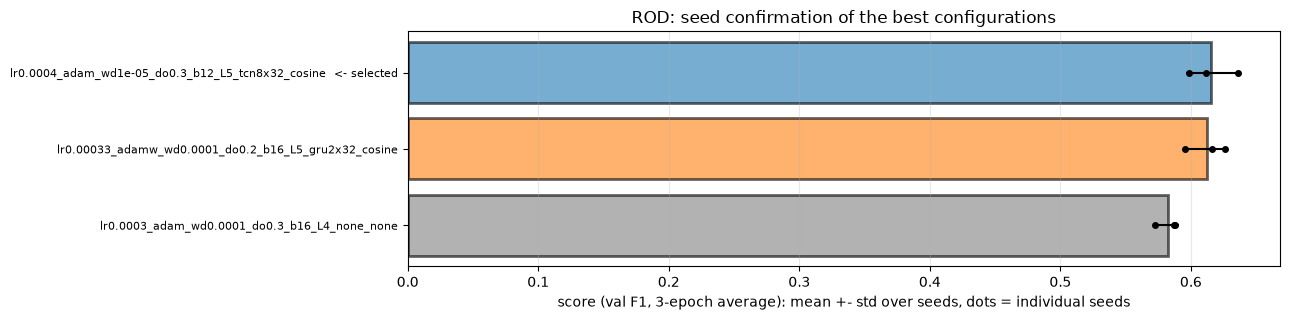

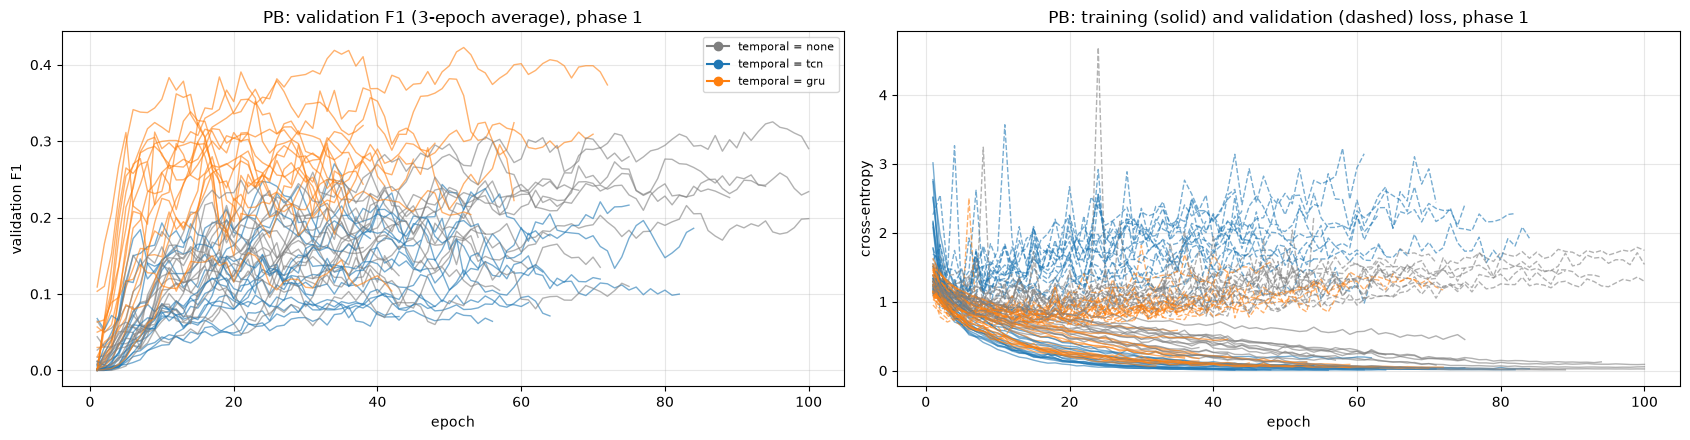

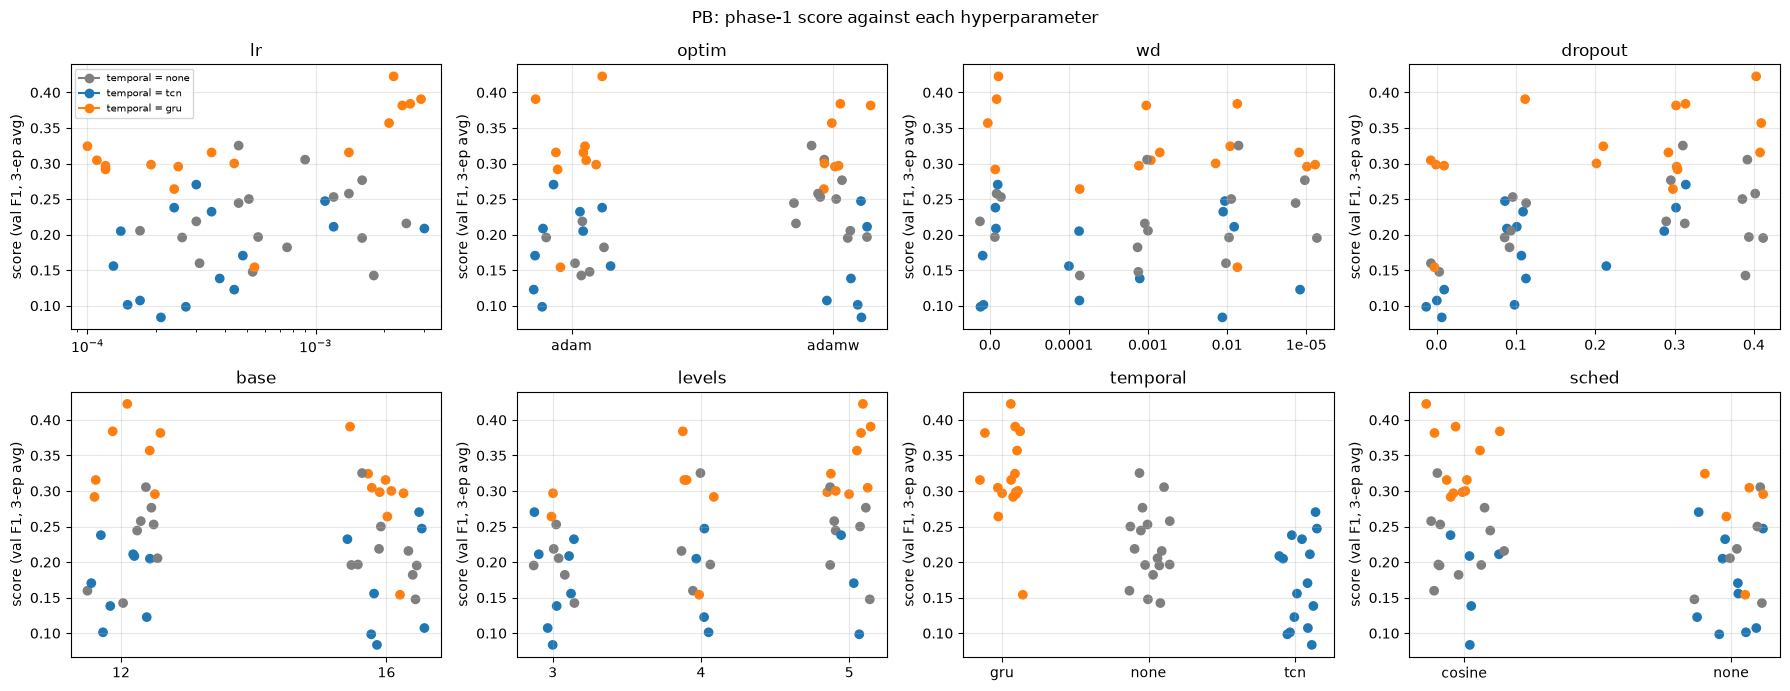

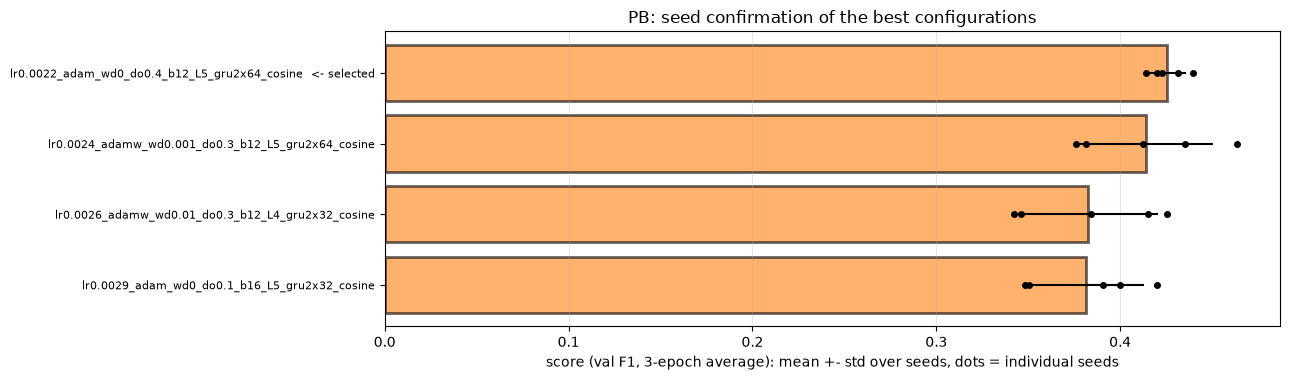

In [14]:
TCOL = {'none': 'tab:gray', 'tcn': 'tab:blue', 'gru': 'tab:orange'}
T_LEGEND = [Line2D([], [], color=c, marker='o', label=f'temporal = {k}') for k, c in TCOL.items()]

def plot_search(ds):
    res = RES[ds]; ok = res[res['status'] == 'ok']; p1 = ok[ok['phase'].str.startswith('phase 1')]
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
    for _, r in p1.iterrows():
        h = pd.DataFrame(HIST.get(r['tag'], []))
        if h.empty: continue
        col = TCOL[r['temporal']]
        ax[0].plot(h['epoch'], h['val_F1_ma'], color=col, alpha=0.6, lw=1)
        ax[1].plot(h['epoch'], h['train_loss'], color=col, alpha=0.6, lw=1)
        ax[1].plot(h['epoch'], h['val_loss'], color=col, alpha=0.6, lw=1, ls='--')
    ax[0].set(title=f'{ds}: validation F1 (3-epoch average), phase 1', xlabel='epoch', ylabel='validation F1'); ax[0].legend(handles=T_LEGEND, fontsize=8)
    ax[1].set(title=f'{ds}: training (solid) and validation (dashed) loss, phase 1', xlabel='epoch', ylabel='cross-entropy')
    for a in ax: a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    hp = ['lr', 'optim', 'wd', 'dropout', 'base', 'levels', 'temporal', 'sched']
    fig, axes = plt.subplots(2, 4, figsize=(18, 7)); jit = np.random.default_rng(0)
    for a, k in zip(axes.ravel(), hp):
        colors = [TCOL[t] for t in p1['temporal']]
        if k == 'lr':
            a.scatter(p1['lr'], p1['best_val_F1_ma'], c=colors); a.set_xscale('log')
        else:
            cats = sorted(p1[k].astype(str).unique()); pos = {c: i for i, c in enumerate(cats)}
            a.scatter([pos[str(v)] + jit.uniform(-0.15, 0.15) for v in p1[k]], p1['best_val_F1_ma'], c=colors)
            a.set_xticks(range(len(cats)), cats)
        a.set(title=k, ylabel='score (val F1, 3-ep avg)'); a.grid(alpha=0.3)
    axes.ravel()[0].legend(handles=T_LEGEND, fontsize=7)
    fig.suptitle(f'{ds}: phase-1 score against each hyperparameter'); plt.tight_layout(); plt.show()

    agg = AGG[ds][AGG[ds]['n_seeds'] > 1].sort_values('score_mean')
    if len(agg):
        fig, a = plt.subplots(figsize=(13, 0.6 * len(agg) + 1.5)); y = np.arange(len(agg))
        a.barh(y, agg['score_mean'], xerr=agg['score_std'].fillna(0), color=[TCOL[t] for t in agg['temporal']], alpha=0.6,
               edgecolor=['k' if k == SELECTED[ds]['key'] else 'none' for k in agg.index], lw=2)
        for yi, k in zip(y, agg.index):
            a.plot(ok[ok['config'] == k]['best_val_F1_ma'], [yi] * int((ok['config'] == k).sum()), 'k.', ms=8)
        a.set_yticks(y, [k + ('  <- selected' if k == SELECTED[ds]['key'] else '') for k in agg.index], fontsize=8)
        a.set(xlabel='score (val F1, 3-epoch average): mean +- std over seeds, dots = individual seeds',
              title=f'{ds}: seed confirmation of the best configurations'); a.grid(axis='x', alpha=0.3)
        plt.tight_layout(); plt.show()

for ds in RES:
    plot_search(ds)

## 11. Selected models on the validation set: receptive field, per-class results and example predictions

For each dataset: the measured temporal receptive field of the selected model (compared with the version-1 model re-trained here as anchor 1), the per-class precision, recall and F1 on the **validation** recordings, and predicted vs ground-truth ornaments on two example recordings. The model shown is the selected configuration trained with seed `SEED`.

ROD version-1 model (anchor) (ROD_lr0.0003_adam_wd0.0001_do0.3_b16_L4_none_none_s2035): receptive field 1.88 s; 90% of the influence within 0.84 s
ROD selected model (ROD_lr0.0004_adam_wd1e-05_do0.3_b12_L5_tcn8x32_cosine_s2035): receptive field 9.24 s; 90% of the influence within 2.00 s
ROD selected model, VALIDATION: {'P': 0.608, 'R': 0.689, 'F1': 0.646, 'F1_any': 0.653, 'F1_iou30': 0.691, 'IoU_macro': 0.561, 'IoU_orn': 0.646, 'IoU_matched': 0.823, 'seg_jaccard': 0.477, 'boundary_acc': 0.469, 'frame_acc': 0.837, 'n_pred': 423.0, 'n_gt': 373.0}


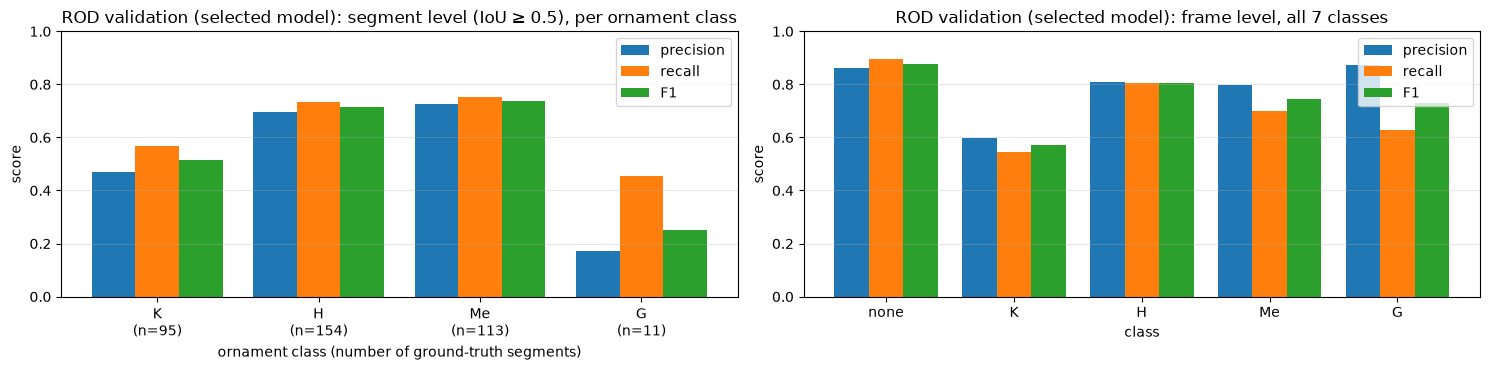

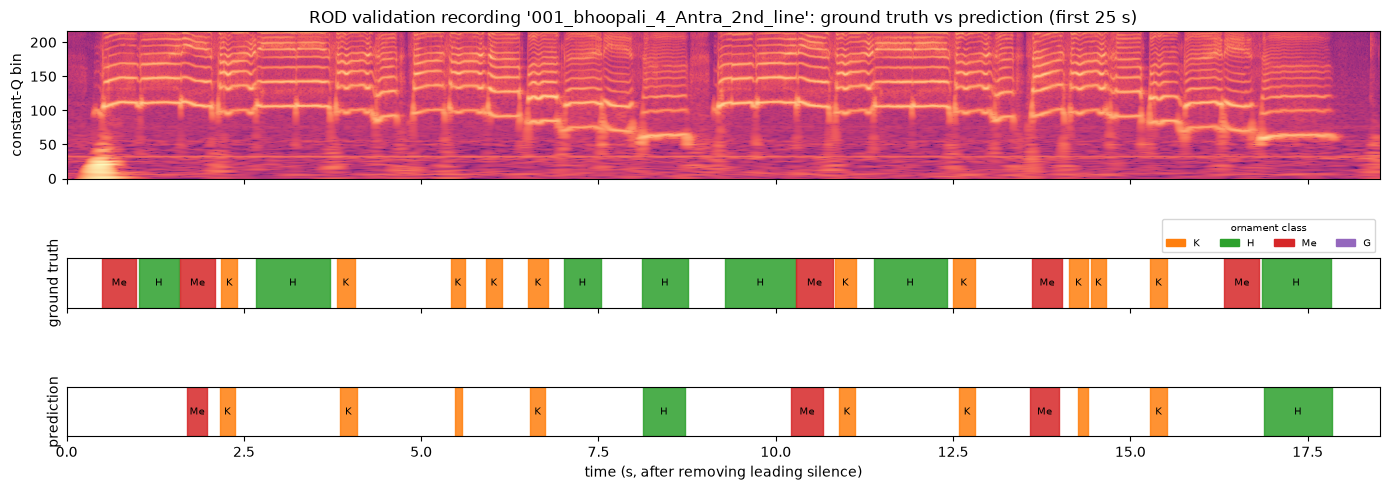

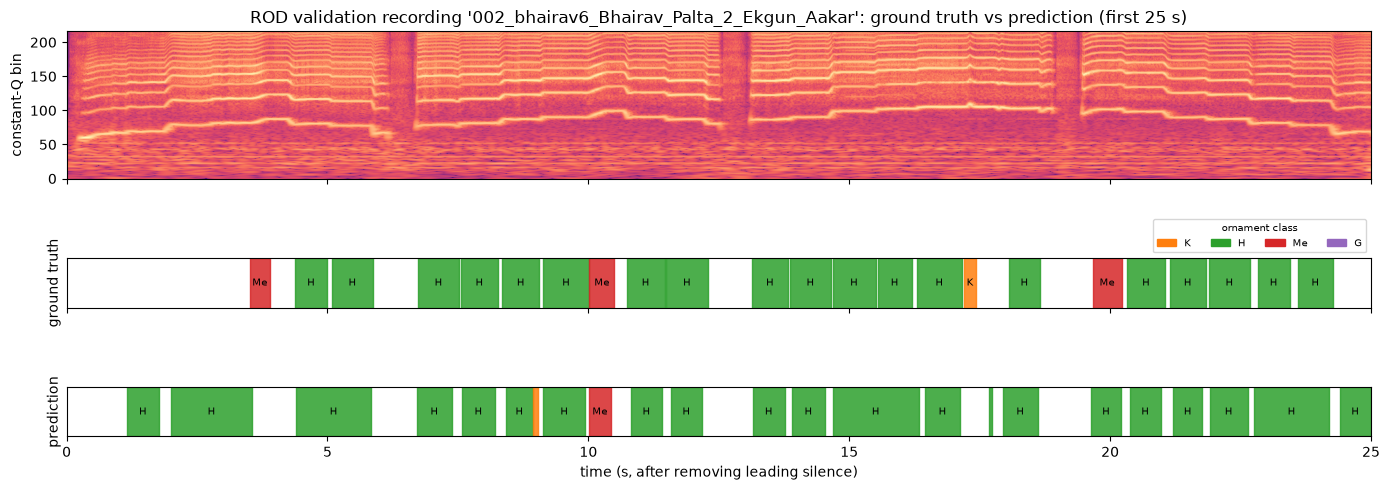

PB version-1 model (anchor) (PB_lr0.0003_adam_wd0_do0.3_b16_L3_none_none_s2035): receptive field 1.76 s; 90% of the influence within 0.92 s
PB selected model (PB_lr0.0022_adam_wd0_do0.4_b12_L5_gru2x64_cosine_s2035): receptive field 30.21 s - reaches the edge of the 30 s measuring window, i.e. effectively the whole input; 90% of the influence within 5.69 s
PB selected model, VALIDATION: {'P': 0.5, 'R': 0.4, 'F1': 0.444, 'F1_any': 0.444, 'F1_iou30': 0.469, 'IoU_macro': 0.272, 'IoU_orn': 0.529, 'IoU_matched': 0.785, 'seg_jaccard': 0.286, 'boundary_acc': 0.067, 'frame_acc': 0.786, 'n_pred': 36.0, 'n_gt': 45.0}


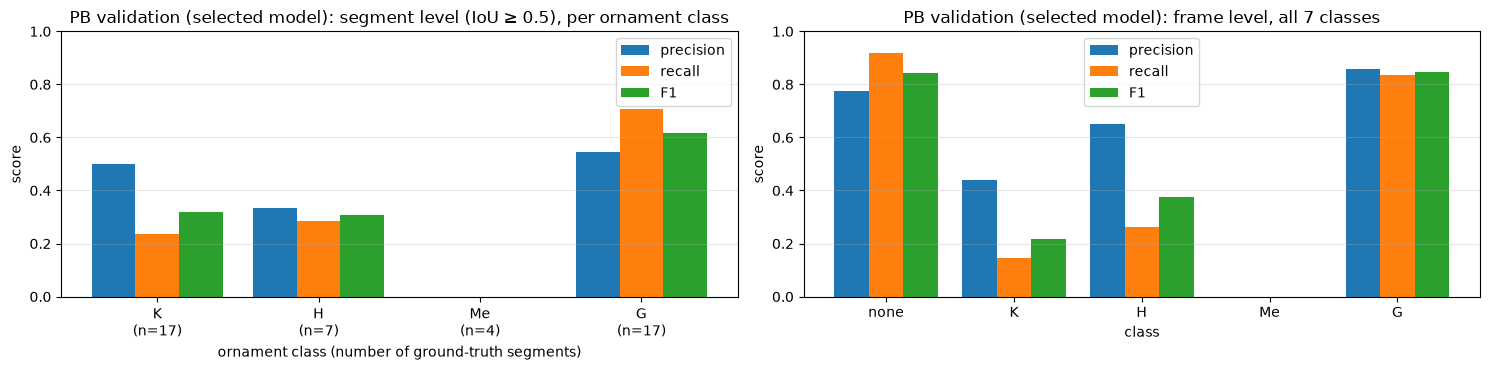

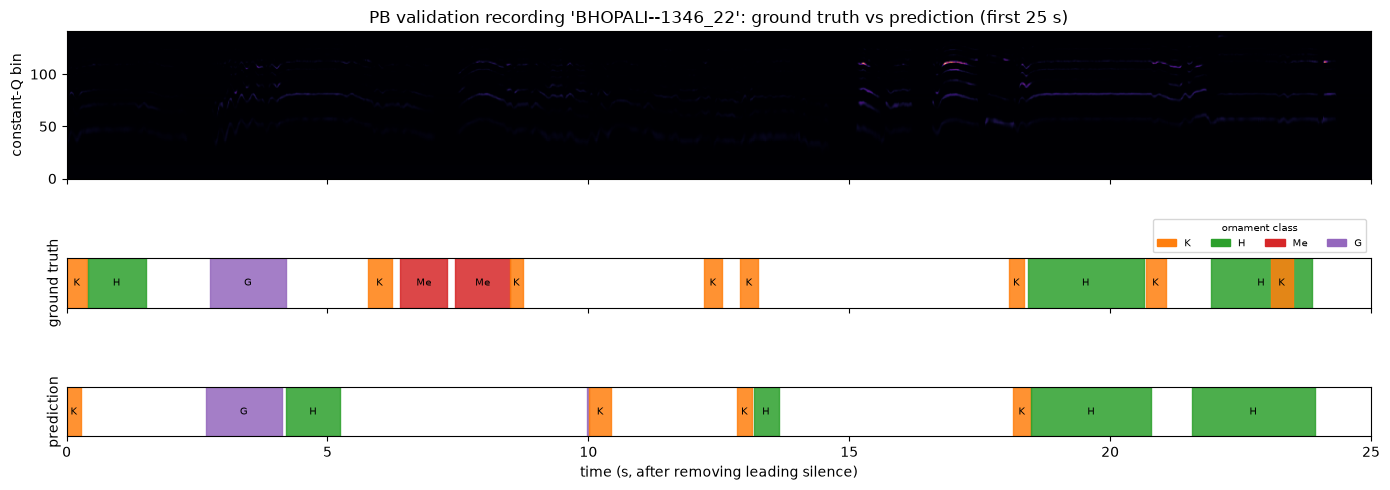

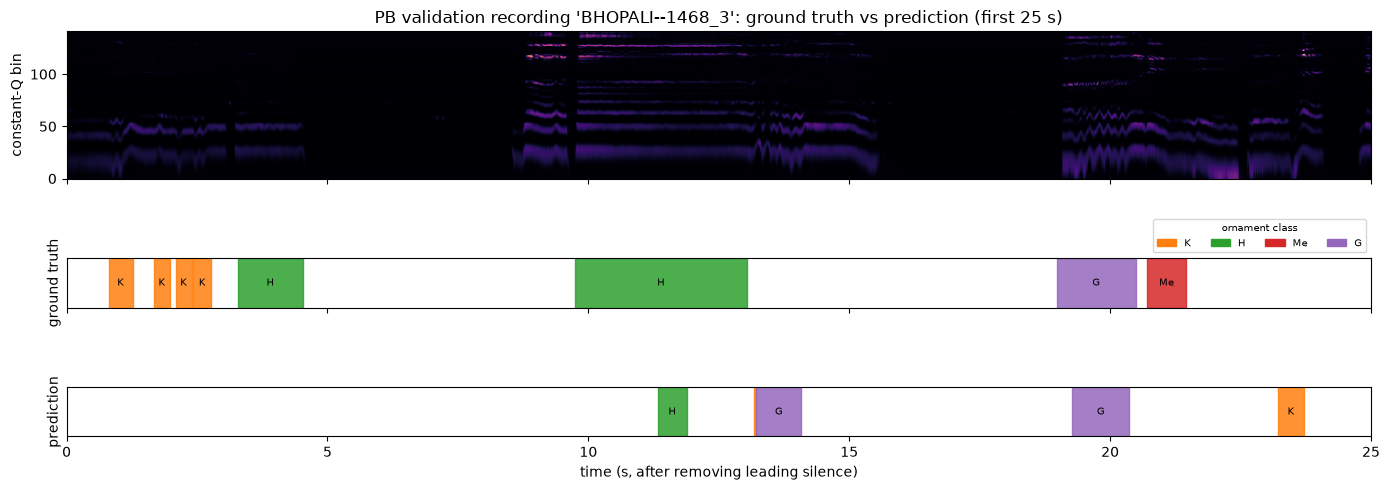

In [15]:
CMAP = plt.get_cmap('tab10')

def plot_per_class(per_class, frame_df, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
    pc = pd.DataFrame(per_class).T; x = np.arange(len(pc)); w = 0.27
    for k, (m, lab) in enumerate((('P', 'precision'), ('R', 'recall'), ('F1', 'F1'))):
        ax[0].bar(x + (k - 1) * w, pc[m], w, label=lab)
    ax[0].set_xticks(x, [f"{c}\n(n={int(pc.loc[c, 'n_gt'])})" for c in pc.index])
    ax[0].set(title=f'{title}: segment level (IoU ≥ 0.5), per ornament class', xlabel='ornament class (number of ground-truth segments)',
              ylabel='score', ylim=(0, 1)); ax[0].legend(); ax[0].grid(axis='y', alpha=0.3)
    x = np.arange(NC)
    for k, m in enumerate(('precision', 'recall', 'F1')):
        ax[1].bar(x + (k - 1) * w, frame_df[m], w, label=m)
    ax[1].set_xticks(x, CLASSES)
    ax[1].set(title=f'{title}: frame level, all 7 classes', xlabel='class', ylabel='score', ylim=(0, 1))
    ax[1].legend(); ax[1].grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

def show_example(data, labs, t, t0s, dur, title):
    fps = t['fps']; a = int(t0s * fps); b = min(len(t['y']), int((t0s + dur) * fps))
    fig, ax = plt.subplots(3, 1, figsize=(14, 5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1, 1]))
    ax[0].imshow(data.x[t['id']][:, a:b].float().numpy(), origin='lower', aspect='auto', cmap='magma',
                 extent=[a / fps, b / fps, 0, data.n_feat])
    ax[0].set(ylabel='constant-Q bin', title=title)
    for row, (name, segs) in enumerate((('ground truth', [(s, e, C2I[l]) for s, e, l in t['segs'] if l]),
                                        ('prediction', [(s / fps, e / fps, c) for s, e, c in runs(labs[t['id']])]))):
        for s, e, c in segs:
            if e > a / fps and s < b / fps:
                s, e = max(s, a / fps), min(e, b / fps)
                ax[row + 1].axvspan(s, e, color=CMAP(c), alpha=0.85)
                if e - s > 0.15: ax[row + 1].text((s + e) / 2, 0.5, CLASSES[c], ha='center', va='center', fontsize=7)
        ax[row + 1].set(yticks=[], ylabel=name)
    ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CMAP(c), label=CLASSES[c]) for c in range(1, NC)],
                 ncol=NC - 1, fontsize=7, loc='upper right', bbox_to_anchor=(1, 1.9), title='ornament class', title_fontsize=7)
    ax[2].set_xlabel('time (s, after removing leading silence)'); plt.tight_layout(); plt.show()

def busiest(tracks, k):
    return sorted(tracks, key=lambda t: -sum(1 for s in t['segs'] if s[2]) / max(t['dur'], 1))[:k]

VAL_LABS = {}
for ds in DATA:
    anchor_tag = tag_of(ds, {**BASE, **ANCHORS[ds][0]}, SEED)
    for label, tag in (('version-1 model (anchor)', anchor_tag), ('selected model', SELECTED[ds]['tags'][0])):
        if not (RUNS / f'{tag}.pt').exists(): continue
        rf = receptive_field(load_model(tag), DATA[ds], DATA[ds].tracks['val'])
        edge = f" - reaches the edge of the {rf['window_s']:.0f} s measuring window, i.e. effectively the whole input" if rf['reaches_window_edge'] else ''
        print(f"{ds} {label} ({tag}): receptive field {rf['theoretical_s']:.2f} s{edge}; 90% of the influence within {rf['effective90_s']:.2f} s")
    torch.cuda.empty_cache()
    model = load_model(SELECTED[ds]['tags'][0])
    VAL_LABS[ds], _ = predict(model, DATA[ds], DATA[ds].tracks['val'])
    m, pc = evaluate(VAL_LABS[ds], DATA[ds].tracks['val']); fr, _ = frame_report(VAL_LABS[ds], DATA[ds].tracks['val'])
    print(f'{ds} selected model, VALIDATION:', {k: round(float(v), 3) for k, v in m.items()})
    plot_per_class(pc, fr, f'{ds} validation (selected model)')
    for t in busiest(DATA[ds].tracks['val'], 2):
        show_example(DATA[ds], VAL_LABS[ds], t, 0.0, 25.0, f"{ds} validation recording '{t['id']}': ground truth vs prediction (first 25 s)")
    del model; torch.cuda.empty_cache()

## 12. Final test evaluation (held-out test recordings)

The configuration was chosen above using validation scores only. Here **every seed** of the selected configuration is run **once** on the test recordings, and the mean and standard deviation over seeds are reported (a single seed would mix the model's quality with the luck of that seed). These numbers are only reported; nothing is changed afterwards. The seed-`SEED` model of each dataset is also saved as `rod_koopman/unet_seg_v2/best_unet_<dataset>.pt` (all seeds are in `runs/`), together with its settings and normalisation statistics.

In [16]:
TEST, TEST_LABS = {}, {}
for ds in DATA:
    per_seed = []
    for k, tag in enumerate(SELECTED[ds]['tags']):
        model = load_model(tag)
        labs, test_loss = predict(model, DATA[ds], DATA[ds].tracks['test'])
        vlabs, _ = predict(model, DATA[ds], DATA[ds].tracks['val'])
        m, pc = evaluate(labs, DATA[ds].tracks['test']); fr, cm = frame_report(labs, DATA[ds].tracks['test'])
        vm, _ = evaluate(vlabs, DATA[ds].tracks['val'])
        per_seed.append(dict(tag=tag, val=vm, test=dict(m, loss=test_loss), test_per_class_segment=pc,
                             test_per_class_frame=fr.to_dict('index'), test_confusion_frames=cm.tolist()))
        if k == 0:
            TEST_LABS[ds] = labs
            torch.save(torch.load(RUNS / f'{tag}.pt', map_location='cpu', weights_only=False), OUT / f'best_unet_{ds}.pt')
        del model; torch.cuda.empty_cache()
    TEST[ds] = dict(selected=SELECTED[ds], seeds=per_seed)

cols = ['P', 'R', 'F1', 'IoU_macro', 'IoU_orn', 'IoU_matched', 'seg_jaccard', 'F1_any', 'F1_iou30', 'boundary_acc', 'frame_acc', 'n_pred', 'n_gt']
rows = {}
for ds in TEST:
    for sp, key in (('validation', 'val'), ('test', 'test')):
        df = pd.DataFrame([s[key] for s in TEST[ds]['seeds']])[cols].astype(float)
        rows[f'{ds} {sp}: mean'] = df.mean(); rows[f'{ds} {sp}: std over seeds'] = df.std()
tab = pd.DataFrame(rows).T.rename(columns=dict(P='precision', R='recall', IoU_macro='IoU (macro, per class)', IoU_orn='IoU (ornament vs none)',
                                               IoU_matched='IoU (matched segments)', seg_jaccard='segment Jaccard TP/(TP+FP+FN)'))
print('Selected configurations:', {ds: TEST[ds]['selected']['key'] for ds in TEST}, '| seeds:', {ds: TEST[ds]['selected']['seeds'] for ds in TEST})
display(tab.round(3))
tab.to_csv(OUT / 'test_results.csv')
for ds in TEST:
    seg = pd.concat([pd.DataFrame(s['test_per_class_segment']).T for s in TEST[ds]['seeds']])
    frm = pd.concat([pd.DataFrame(s['test_per_class_frame']).T for s in TEST[ds]['seeds']])
    print(f'{ds} TEST, per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), mean over seeds')
    display(seg.groupby(level=0, sort=False).mean().round(3))
    print(f'{ds} TEST, per class (frame level), mean over seeds'); display(frm.groupby(level=0, sort=False).mean().round(3))
json.dump(TEST, open(OUT / 'final_results.json', 'w'), indent=1, default=float)
print('saved:', OUT / 'test_results.csv', '|', OUT / 'final_results.json', '|', [str(OUT / f'best_unet_{ds}.pt') for ds in TEST])

Selected configurations: {'ROD': 'lr0.0004_adam_wd1e-05_do0.3_b12_L5_tcn8x32_cosine', 'PB': 'lr0.0022_adam_wd0_do0.4_b12_L5_gru2x64_cosine'} | seeds: {'ROD': [2035, 2036, 2037], 'PB': [2035, 2036, 2037, 2038, 2039]}


,precision,recall,F1,"IoU (macro, per class)",IoU (ornament vs none),IoU (matched segments),segment Jaccard TP/(TP+FP+FN),F1_any,F1_iou30,boundary_acc,frame_acc,n_pred,n_gt
ROD validation: mean,0.571,0.672,0.616,0.578,0.656,0.831,0.446,0.623,0.675,0.458,0.837,441.333,373.0
ROD validation: std over seeds,0.049,0.025,0.029,0.017,0.009,0.007,0.030,0.032,0.015,0.028,0.003,47.248,0.0
ROD test: mean,0.466,0.635,0.537,0.524,0.645,0.828,0.367,0.545,0.598,0.439,0.836,1200.333,881.0
ROD test: std over seeds,0.010,0.019,0.003,0.032,0.009,0.004,0.003,0.006,0.006,0.015,0.004,60.144,0.0
PB validation: mean,0.468,0.413,0.438,0.322,0.585,0.796,0.280,0.475,0.480,0.076,0.789,40.000,45.0
PB validation: std over seeds,0.033,0.030,0.012,0.047,0.058,0.022,0.010,0.032,0.015,0.025,0.039,5.431,0.0
PB test: mean,0.396,0.321,0.351,0.323,0.478,0.770,0.213,0.379,0.437,0.085,0.740,51.200,61.0
PB test: std over seeds,0.085,0.046,0.047,0.029,0.034,0.036,0.035,0.040,0.040,0.014,0.020,12.008,0.0


ROD TEST, per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), mean over seeds


,P,R,F1,frame_IoU,n_gt,n_pred
K,0.342,0.441,0.381,0.296,241.0,316.667
H,0.556,0.777,0.648,0.717,360.0,503.333
Me,0.535,0.656,0.589,0.491,256.0,314.000
G,0.113,0.222,0.143,0.592,24.0,66.333


ROD TEST, per class (frame level), mean over seeds


,precision,recall,F1,IoU,gt_frames,pred_frames
none,0.892,0.871,0.881,0.787,121406.0,118606.000
K,0.476,0.455,0.457,0.296,6140.0,6074.333
H,0.803,0.870,0.835,0.717,39067.0,42357.333
Me,0.648,0.674,0.659,0.491,15024.0,15677.667
G,0.858,0.657,0.738,0.592,4615.0,3536.667


PB TEST, per ornament class (segment level, IoU >= 0.5; frame_IoU is frame level), mean over seeds


,P,R,F1,frame_IoU,n_gt,n_pred
K,0.177,0.126,0.138,0.108,19.0,14.2
H,0.645,0.438,0.515,0.465,21.0,14.8
Me,0.280,0.314,0.292,0.260,14.0,15.4
G,0.543,0.514,0.524,0.461,7.0,6.8


PB TEST, per class (frame level), mean over seeds


,precision,recall,F1,IoU,gt_frames,pred_frames
none,0.771,0.902,0.831,0.711,6342.0,7420.2
K,0.255,0.171,0.191,0.108,377.0,253.2
H,0.759,0.550,0.633,0.465,2269.0,1655.2
Me,0.468,0.387,0.410,0.260,716.0,609.6
G,0.945,0.475,0.627,0.461,473.0,238.8


saved: C:\Users\YOGESH KRISHNA\Desktop\smai-project\smai-project\rod_koopman\unet_seg_v2\test_results.csv | C:\Users\YOGESH KRISHNA\Desktop\smai-project\smai-project\rod_koopman\unet_seg_v2\final_results.json | ['C:\\Users\\YOGESH KRISHNA\\Desktop\\smai-project\\smai-project\\rod_koopman\\unet_seg_v2\\best_unet_ROD.pt', 'C:\\Users\\YOGESH KRISHNA\\Desktop\\smai-project\\smai-project\\rod_koopman\\unet_seg_v2\\best_unet_PB.pt']


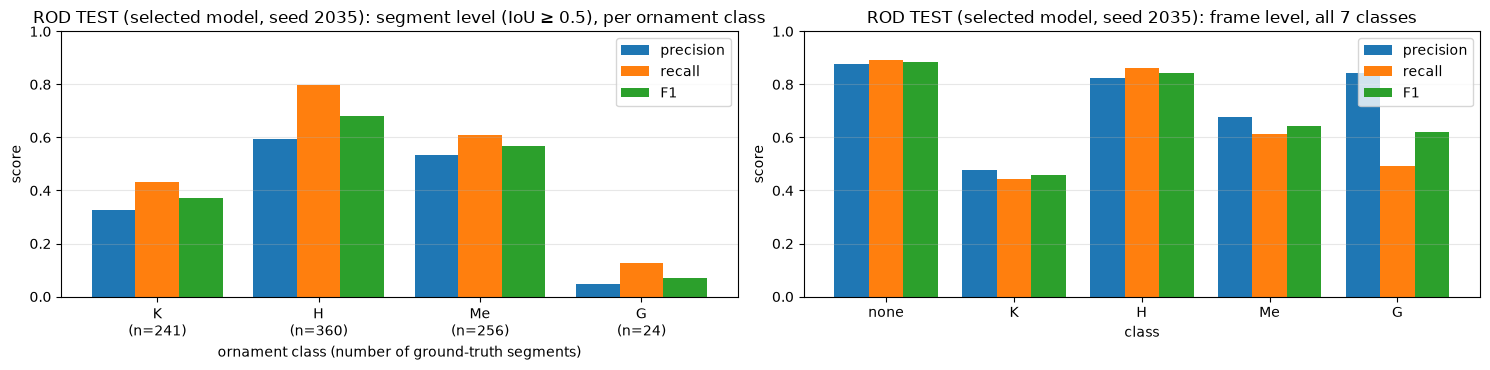

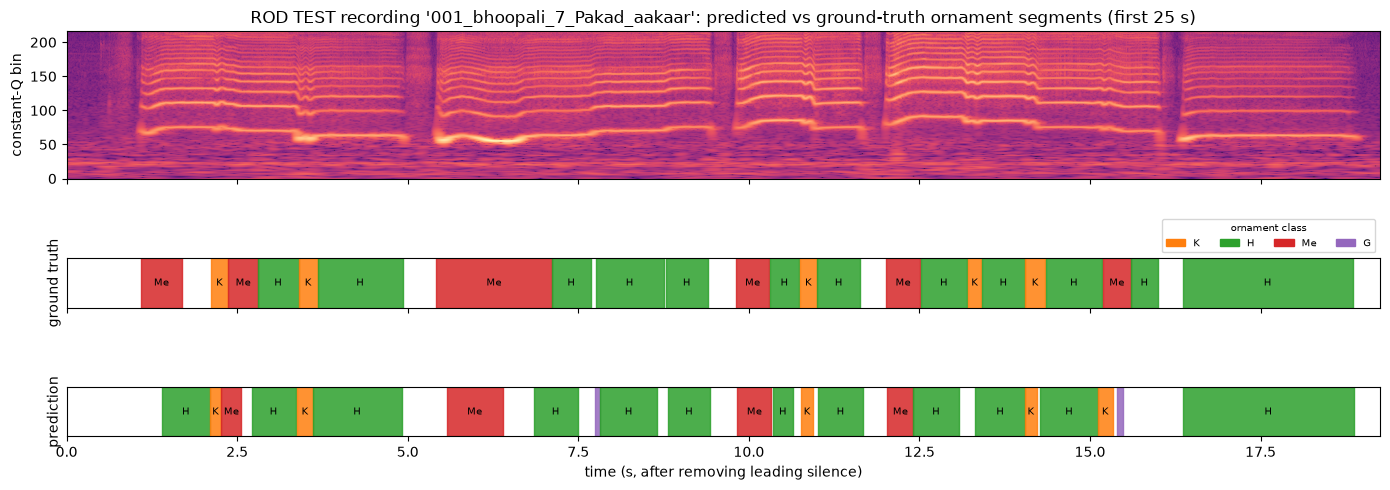

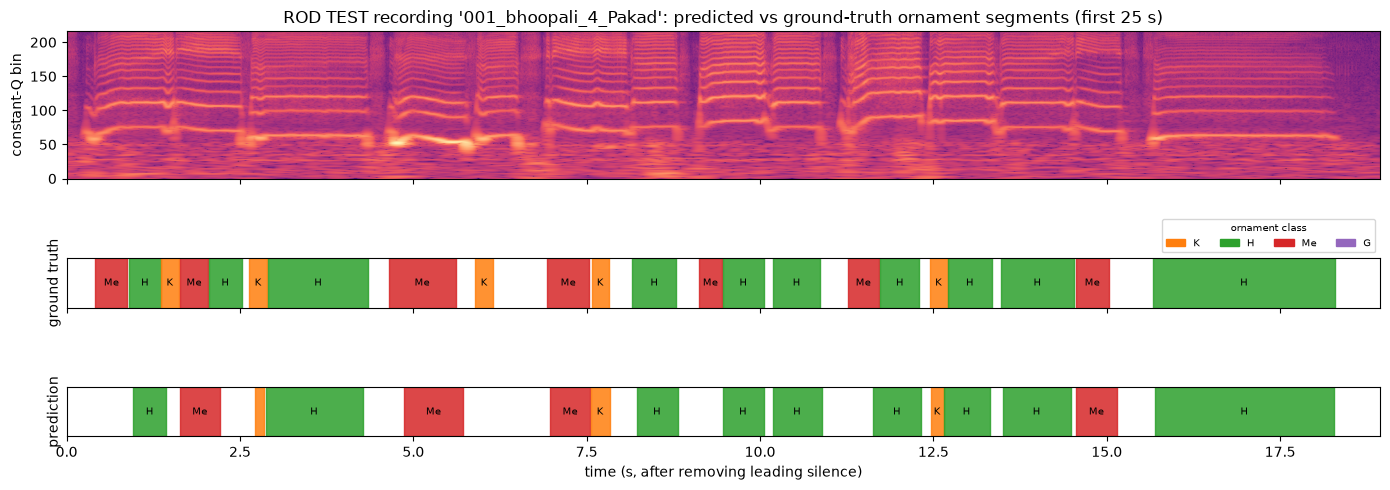

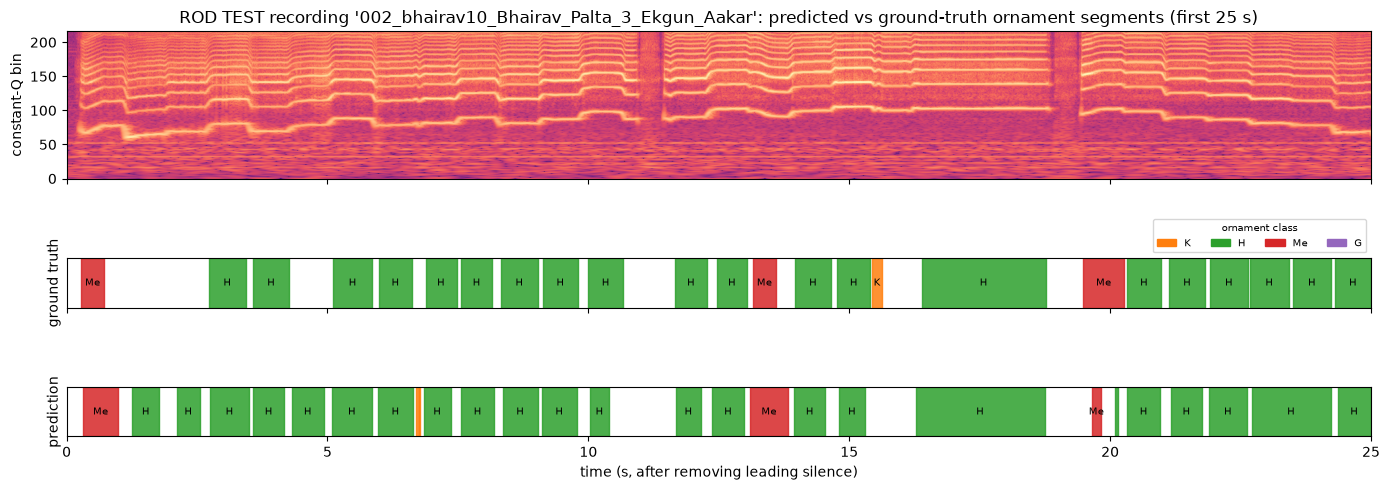

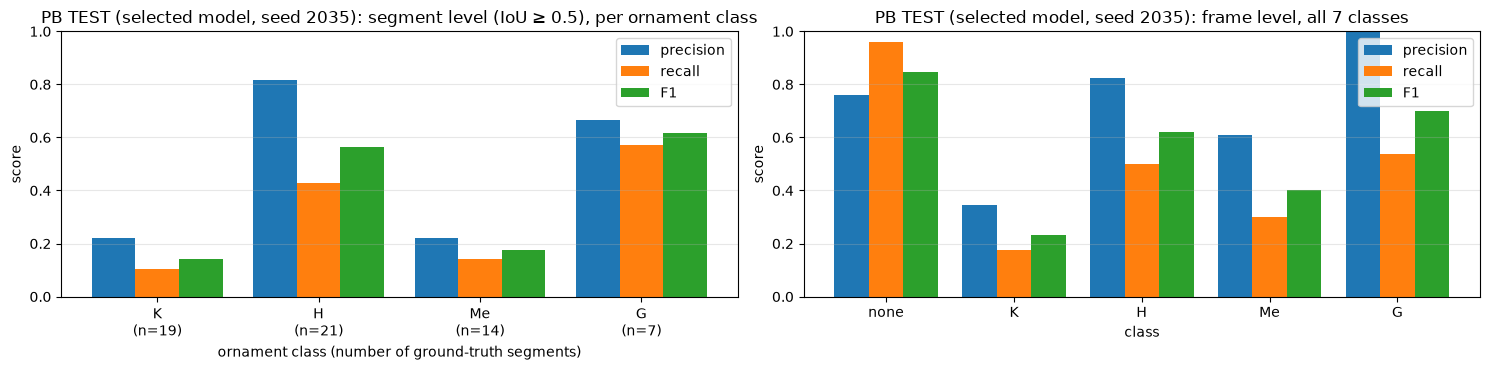

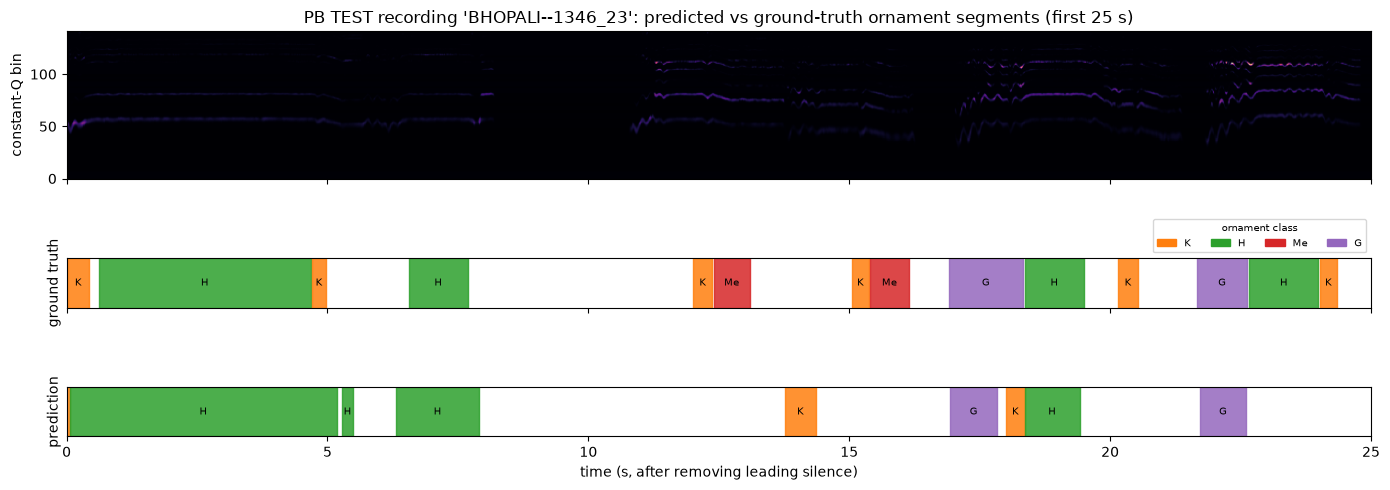

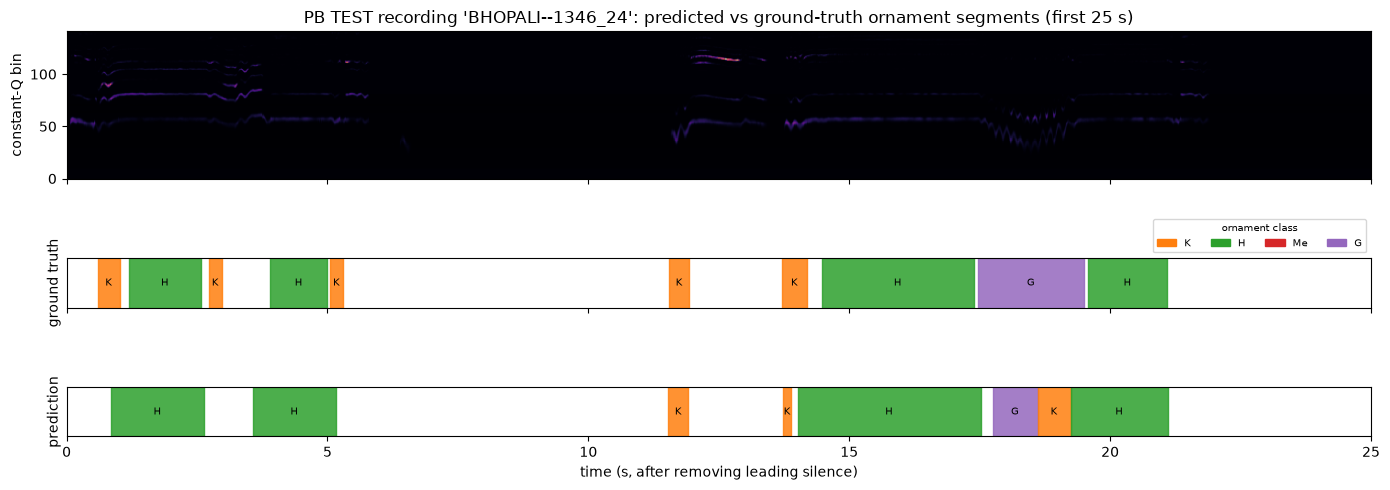

In [17]:
for ds in TEST:
    s0 = TEST[ds]['seeds'][0]
    plot_per_class(s0['test_per_class_segment'], pd.DataFrame(s0['test_per_class_frame']).T, f'{ds} TEST (selected model, seed {SEED})')
    for t in busiest(DATA[ds].tracks['test'], 3 if ds == 'ROD' else 2):
        show_example(DATA[ds], TEST_LABS[ds], t, 0.0, 25.0, f"{ds} TEST recording '{t['id']}': predicted vs ground-truth ornament segments (first 25 s)")

## Notes

* **Data**: only the saved cache is used, with the original splits (lists saved in `splits.json`). `Mu` and `An` are relabelled as `none` (5 classes). The only preprocessing is removing silence at the start and end of each recording (training recordings may use their labels to avoid cutting an annotation; validation and test recordings are cut from the audio alone), then per-bin normalisation from the training split.
* **Model and training**: a 2D U-Net on the full CQT of each recording, optionally followed by a dilated temporal convolution stack or a bidirectional GRU for long temporal context; plain cross-entropy without class weights, no augmentation, one whole recording per step; checkpoint chosen on a 3-epoch average of validation F1.
* **Selection**: random search over all settings jointly, then the best configurations re-trained with several seeds; the configuration with the best mean validation score is selected. The test set was used once, at the very end, for every seed of the selected configuration.
* **Version 1 vs version 2 numbers**: version 2 has 5 classes instead of 7, so its scores are **not directly comparable** with version 1 (`rod_koopman/unet_seg/`). Anchor 1 of the search is the version-1 configuration trained on the 5-class data, which is the fair comparison point.
* **Saved outputs** (`rod_koopman/unet_seg_v2/`): `runs/*.json` and `runs/*.pt` (every experiment and seed), `search_results_*.csv`, `search_summary_*.csv`, `selected_models.json`, `splits.json`, `best_unet_ROD.pt` / `best_unet_PB.pt`, `test_results.csv` and `final_results.json`.
* **Memory / failures**: configurations that needed more than the 4 GB of GPU memory were run with spill into shared system RAM and are flagged `uses_shared_memory` (correct, but slower). Out-of-memory errors and other failed experiments are marked in the search tables with their error message. They were not shortened or retried with crops.